# **Proyecto Final Bioinformática: ¿Qué genes activa la estimulación eléctrica en las células de la piel?**
*Datasets: GSE110830 y GSE80178 (GEO, NCBI)*

Bioinformática 2026 – Bioingeniería, UNSTA

Profesor: Ignacio Labari

Alumno: Solana Cueto Mas

Proyecto Final

## **1- Experimentos, datasets y objetivo**

Me interesa la **estimulación eléctrica** como terapia para curar heridas. Cuando la piel se lastima se genera un campo eléctrico natural en el borde de la herida (de 40 a 200 mV/mm) que guía a las células para que migren y la cierren. La idea de la terapia es aplicar ese estímulo desde afuera, por ejemplo con parches, sobre todo en heridas que no cierran solas como las **úlceras de pie diabético** (Preetam et al., 2024). En esa revisión se proponen varios mecanismos (receptor EGFR, vía MAPK-ERK, PI3K/Akt, canales de calcio), pero todavía no está claro qué pasa dentro de la célula cuando recibe la corriente.

### **Dataset 1: GSE110830 (estimulación eléctrica en células de la piel)**

**Paper cabecera:** Aoki M., Ogai K., Matsumoto M., Sugama J., Okamoto S. (2019). *Cytochrome P450 genes play central roles in transcriptional response by keratinocytes to a high-voltage alternating current electric field.* Bioelectrochemistry. doi:10.1016/j.bioelechem.2018.11.014. Los datos los subió el Departamento de Cirugía Plástica de la Nippon Medical School (Tokio, Japón).

Cultivaron 3 tipos de células de la piel que participan en la cicatrización:
- **Queratinocitos** (línea HaCaT): las células de la epidermis, las que cierran la herida desde arriba.
- **Fibroblastos dérmicos** (NHDF): fabrican colágeno y rellenan la herida.
- **Células endoteliales** (HMEC-1): forman los vasos sanguíneos nuevos.

A cada tipo celular le aplicaron un campo eléctrico de alto voltaje (14000 V, 90 Hz, durante 6 horas) con el equipo SE-14000, y lo compararon contra células control (*sham*, que pasan por lo mismo pero sin corriente). Hicieron 3 réplicas biológicas de cada tipo celular y midieron la expresión de todos los genes con un **microarray de Agilent de dos colores** (plataforma GPL20844): en cada chip se pone el ARN de las células estimuladas (marcado con Cy5, rojo) junto con el de las sham (marcado con Cy3, verde). Por eso cada valor ya es una comparación: el **log ratio estimulado/sham**. Positivo = el gen se activó con la corriente; negativo = se apagó; 0 = no cambió.

### **Dataset 2: GSE80178 (úlcera de pie diabético)**

**Paper:** Ramirez H.A., Pastar I., Jozic I., Stojadinovic O., Stone R.C., Ojeh N., Gil J., Davis S.C., Kirsner R.S., Tomic-Canic M. (2018). *Staphylococcus aureus triggers induction of miR-15B-5P to diminish DNA repair and deregulate inflammatory response in diabetic foot ulcers.* Journal of Investigative Dermatology, 138(5), 1187-1196. doi:10.1016/j.jid.2017.11.038. Universidad de Miami (EE. UU.).

Compararon biopsias del borde de **6 úlceras de pie diabético** contra **6 muestras de piel de pie sin úlcera** (microarray de Affymetrix). En GEO subieron la **tabla de resultados** de esa comparación: los genes que cambian en la úlcera (FDR < 0,05 y al menos 2 veces de cambio).

### **Objetivos**
1. Ver qué genes cambian cuando las células de la piel reciben el campo eléctrico, y si los 3 tipos celulares responden igual.
2. Ver si esos genes tienen que ver con los mecanismos que propone la literatura (EGFR, MAPK-ERK, estrés oxidativo).
3. Ver si los genes que activa la corriente también están alterados en una úlcera diabética real.
4. Elegir un gen que produzca una proteína liberada al exterior, para usarlo como biomarcador en el proyecto de Biosensores.

### **Hipótesis**
La estimulación eléctrica induciría en los queratinocitos un programa transcripcional propio, distinto del de los fibroblastos y las células endoteliales, que incluiría genes de la vía **EGFR → MAPK-ERK** y de defensa frente al **estrés oxidativo**. Parte de ese programa coincidiría con el que está activado en el borde de una úlcera de pie diabético, y entre esos genes habría al menos uno que codifique una **proteína secretada**, que se pueda medir en el exudado de la herida.

## **2- Abrir los conjuntos de datos**

Los archivos se descargaron de GEO y se subieron a la sesión de Colab: la *series matrix* de GSE110830, la anotación de la plataforma GPL20844 y la tabla de resultados de GSE80178. En la *series matrix*, las líneas que empiezan con `!` son información del experimento y después viene la tabla de datos.

In [1]:
# Archivos subidos a la sesión de Colab
!ls -lh *.txt

-rw-r--r-- 1 root root  36M Nov 15 18:44 GPL20844.txt
-rw-r--r-- 1 root root 3.8M Nov 15 19:02 GSE110830_series_matrix.txt
-rw-r--r-- 1 root root 469K Nov 15 18:50 GSE80178_further_processed_data.txt


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Las líneas que empiezan con "!" son información del experimento, con comment='!' pandas las saltea
datos = pd.read_csv('GSE110830_series_matrix.txt', sep='\t', comment='!', index_col=0)
datos

,GSM3017478,GSM3017479,GSM3017480,GSM3017481,GSM3017482,GSM3017483,GSM3017484,GSM3017485,GSM3017486
ID_REF,,,,,,,,,
1,-0.035,-0.027,-0.031,0.012,-0.024,-0.035,-0.060,-0.042,-0.066
2,0.000,0.000,0.000,0.000,0.000,0.000,-0.375,0.000,0.000
3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.385,0.404,-0.005,0.034,-0.168,0.005,0.056,0.122,0.110
5,0.000,0.000,0.000,-0.013,-0.068,0.012,-0.214,0.243,0.148
...,...,...,...,...,...,...,...,...,...
62972,0.000,-0.494,0.000,0.000,0.077,0.000,-0.423,0.174,0.000
62973,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
62974,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [4]:
# Ver los títulos de las muestras, en el mismo orden que las columnas
!grep "Sample_title" GSE110830_series_matrix.txt

!Sample_title	"SE-14000 stimulated Human keratinocyte cells vs. sham 1"	"SE-14000 stimulated Human keratinocyte cells vs. sham 2"	"SE-14000 stimulated Human keratinocyte cells vs. sham 3"	"SE-14000 stimulated Normal Human Dermal Fibroblasts vs. sham 1"	"SE-14000 stimulated Normal Human Dermal Fibroblasts vs. sham 2"	"SE-14000 stimulated Normal Human Dermal Fibroblasts vs. sham 3"	"SE-14000 stimulated Human Microvascular Endotheilal Cells vs. sham 1"	"SE-14000 stimulated Human Microvascular Endotheilal Cells vs. sham 2"	"SE-14000 stimulated Human Microvascular Endotheilal Cells vs. sham 3"


In [5]:
# Definir nombres de columnas (en el orden de los títulos de arriba)
column_names = ['Querat_1', 'Querat_2', 'Querat_3',
                'Fibro_1', 'Fibro_2', 'Fibro_3',
                'Endot_1', 'Endot_2', 'Endot_3']

datos.columns = column_names

datos

,Querat_1,Querat_2,Querat_3,Fibro_1,Fibro_2,Fibro_3,Endot_1,Endot_2,Endot_3
ID_REF,,,,,,,,,
1,-0.035,-0.027,-0.031,0.012,-0.024,-0.035,-0.060,-0.042,-0.066
2,0.000,0.000,0.000,0.000,0.000,0.000,-0.375,0.000,0.000
3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0.385,0.404,-0.005,0.034,-0.168,0.005,0.056,0.122,0.110
5,0.000,0.000,0.000,-0.013,-0.068,0.012,-0.214,0.243,0.148
...,...,...,...,...,...,...,...,...,...
62972,0.000,-0.494,0.000,0.000,0.077,0.000,-0.423,0.174,0.000
62973,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
62974,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [6]:
datos.shape

(62976, 9)

**¿Cuántas filas y columnas hay? ¿Qué es cada una?**

Hay **62.976 filas y 9 columnas**.

Cada **columna es una muestra**: un chip donde se hibridó el ARN de un cultivo estimulado junto con el de su control sham. Son 3 tipos celulares × 3 réplicas.

Cada **fila es una sonda** del microarray, o sea un fragmento de ADN pegado al chip que mide la expresión de un gen. La mayoría son de genes y algunas son controles del chip.


La columna de las sondas solo tiene un número (`ID_REF`). Para saber qué gen mide cada sonda descargo la **anotación de la plataforma** GPL20844 con la librería `GEOparse`.

In [7]:
!pip install -q GEOparse
import GEOparse

gpl = GEOparse.get_GEO(filepath="GPL20844.txt")
print(gpl.table.columns)

15-Nov-2026 19:45:22 INFO GEOparse - Parsing GPL20844.txt: 
INFO:GEOparse:Parsing GPL20844.txt: 
15-Nov-2026 19:45:22 DEBUG GEOparse - PLATFORM: GPL20844
DEBUG:GEOparse:PLATFORM: GPL20844
15-Nov-2026 19:45:23 WARNING GEOTypes - Detected duplicated columns in d GPL20844. Correcting.




Index(['ID', 'COL', 'ROW', 'NAME', 'SPOT_ID', 'CONTROL_TYPE', 'REFSEQ',
       'GB_ACC', 'LOCUSLINK_ID', 'GENE_SYMBOL', 'GENE_NAME', 'UNIGENE_ID',
       'ENSEMBL_ID', 'TIGR_ID', 'ACCESSION_STRING', 'CHROMOSOMAL_LOCATION',
       'CYTOBAND', 'DESCRIPTION', 'GO_ID', 'SEQUENCE', 'SPOT_ID.1'],
      dtype='object')


In [8]:
# Me quedo con el ID de la sonda, el nombre del gen y el código RefSeq
anotacion = gpl.table[['ID', 'GENE_SYMBOL', 'REFSEQ']].copy()
anotacion['ID'] = anotacion['ID'].astype(str)

anotacion

,ID,GENE_SYMBOL,REFSEQ
0,1,NaN,NaN
1,2,NaN,NaN
2,3,NaN,NaN
3,4,NaN,NaN
4,5,CPED1,NM_001105533
...,...,...,...
62971,62972,PNMA3,NM_013364
62972,62973,NaN,NaN
62973,62974,NaN,NaN
62974,62975,NaN,NaN


In [9]:
# Ver cómo procesaron los datos
!grep "data_processing" GSE110830_series_matrix.txt | cut -c1-200

!Sample_data_processing	"LOWESS normalized, background subtracted VALUE data obtained from log10 of processed Red signal/processed Green signal. Agilent software was used."	"LOWESS normalized, backgro


**¿En qué unidades están los datos?**

En `data_processing` dice que los valores son el **log10** de la señal roja (estimulado) sobre la verde (sham), normalizados con LOWESS. Los paso a **log2**, que es la escala que se usa siempre en transcriptómica: un log2 de 1 quiere decir que el gen está el doble de expresado con la corriente, y un -1 que está a la mitad.

In [10]:
datos = datos * np.log2(10)   #aca entonces paso de log10 a log2

In [11]:
# Ver el resumen estadístico
summary = datos.describe()
print(summary)

           Querat_1      Querat_2      Querat_3       Fibro_1       Fibro_2  \
count  62976.000000  62976.000000  62976.000000  62976.000000  62976.000000   
mean      -0.010836     -0.001236     -0.013643      0.004135     -0.008331   
std        0.484318      0.508329      0.473577      0.499881      0.482102   
min       -4.717138     -4.936385     -5.544298     -6.308341     -4.876590   
25%       -0.076404     -0.069760     -0.086370     -0.112946     -0.083048   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.089692      0.073082      0.099658      0.159453      0.106302   
max        3.431552     10.072086      3.165797      2.996379      2.770488   

            Fibro_3       Endot_1       Endot_2       Endot_3  
count  62976.000000  62976.000000  62976.000000  62976.000000  
mean      -0.012433     -0.014351     -0.012223     -0.007490  
std        0.527098      0.473260      0.482411      0.493232  
min       -7.265057     -5.07590

**¿Cuáles son los mínimos y máximos? ¿Dónde está la mayoría de los valores?**

La **media de todas las muestras está entre -0,014 y 0,004** y la **mediana es 0**. El 50 % central de los datos está más o menos entre -0,1 y 0,15 (en log2), o sea que la gran mayoría de las sondas casi no cambia con la corriente, que es lo esperable.

Los mínimos van de -4,7 a -7,3 y los máximos de 2,8 a 3,4, salvo Querat_2, que tiene un máximo de 10,1 (más de 1000 veces). Ese valor tan extremo en una sola réplica es sospechoso de ser un error de medición de una sonda.

La mediana da exactamente 0 porque muchísimos valores son 0, lo que reviso en el paso siguiente.

## **3- Preparación de los datos**

In [12]:
datos.isnull().sum()

,0
Querat_1,0
Querat_2,0
Querat_3,0
Fibro_1,0
Fibro_2,0
Fibro_3,0
Endot_1,0
Endot_2,0
Endot_3,0


In [13]:
# Contar cuántos valores son exactamente 0
(datos == 0).sum()

,0
Querat_1,20206
Querat_2,21764
Querat_3,20571
Fibro_1,19466
Fibro_2,19758
Fibro_3,19827
Endot_1,20650
Endot_2,20538
Endot_3,19349


**¿Hay valores faltantes?**

Con `isnull()` no aparece ninguno, pero hay **entre 19.349 y 21.764 valores que son exactamente 0 en cada muestra (entre el 31 y el 35 %)**. Eso no quiere decir que el gen no cambió: el software de Agilent pone 0 cuando la sonda no tuvo señal confiable (no se detectó bien). Por eso los trato como faltantes y los reemplazo por `NaN`.

In [14]:
datos = datos.replace(0, np.nan)
datos.isnull().sum()

,0
Querat_1,20206
Querat_2,21764
Querat_3,20571
Fibro_1,19466
Fibro_2,19758
Fibro_3,19827
Endot_1,20650
Endot_2,20538
Endot_3,19349


In [15]:
# Agregar el nombre del gen y el RefSeq a cada sonda
datos.index = datos.index.astype(str)
datos = datos.merge(anotacion, left_index=True, right_on='ID')

datos

,Querat_1,Querat_2,Querat_3,Fibro_1,Fibro_2,Fibro_3,Endot_1,Endot_2,Endot_3,ID,GENE_SYMBOL,REFSEQ
0,-0.116267,-0.089692,-0.102980,0.039863,-0.079726,-0.116267,-0.199316,-0.139521,-0.219247,1,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,-1.245723,NaN,NaN,2,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN
3,1.278942,1.342059,-0.016610,0.112946,-0.558084,0.016610,0.186028,0.405275,0.365412,4,NaN,NaN
4,NaN,NaN,NaN,-0.043185,-0.225891,0.039863,-0.710893,0.807229,0.491645,5,CPED1,NM_001105533
...,...,...,...,...,...,...,...,...,...,...,...,...
62971,NaN,-1.641032,NaN,NaN,0.255788,NaN,-1.405176,0.578015,NaN,62972,PNMA3,NM_013364
62972,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62973,NaN,NaN
62973,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62974,NaN,NaN
62974,-0.019932,-0.019932,-0.029897,0.109624,-0.023253,-0.026575,-0.106302,-0.039863,-0.129555,62975,NaN,NaN


**Filtro de genes codificantes de proteína.** En el primer análisis muchos de los genes que "cambiaban" eran ARN no codificantes (`lnc-...`, `LOC...`), que son difíciles de interpretar y no sirven como biomarcador porque no dan una proteína. Para quedarme solo con los que codifican proteína uso el código **RefSeq**: los que empiezan con **`NM_`** son ARN mensajeros (codificantes) y los que empiezan con `NR_` son no codificantes.

In [16]:
print("Sondas totales:", len(datos))

# Me quedo con las sondas de genes codificantes (RefSeq NM_)
datos = datos[datos['REFSEQ'].astype(str).str.startswith('NM_')]
print("Sondas de genes codificantes:", len(datos))

Sondas totales: 62976
Sondas de genes codificantes: 27937


In [17]:
# Si un gen tiene varias sondas, me quedo con la mediana
datos_limpios = datos.groupby('GENE_SYMBOL')[column_names].median()

datos_limpios.to_csv('datos_limpios_GSE110830.csv')

print("Genes:", len(datos_limpios))
datos_limpios

Genes: 18558


,Querat_1,Querat_2,Querat_3,Fibro_1,Fibro_2,Fibro_3,Endot_1,Endot_2,Endot_3
GENE_SYMBOL,,,,,,,,,
A1BG,0.106302,0.186028,0.511577,0.315583,0.083048,0.252467,0.112946,0.142843,0.265754
A1CF,NaN,0.083048,NaN,0.481680,NaN,NaN,NaN,NaN,-1.634389
A2M,NaN,NaN,NaN,0.383683,-0.124572,0.400292,-1.368634,0.124572,-0.950071
A2ML1,-0.275720,0.624522,0.405275,NaN,NaN,NaN,NaN,NaN,NaN
A3GALT2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
ZYG11A,NaN,NaN,NaN,-0.970003,0.632827,0.182706,0.041524,0.413580,0.039863
ZYG11B,-0.159453,-0.058134,-0.059795,0.197655,-0.084709,0.046507,-0.033219,-0.099658,0.000000
ZYX,0.053151,-0.069760,0.006644,0.013288,-0.023253,0.106302,0.049829,-0.009966,-0.056473


In [18]:
# ¿Cuántos genes tienen las 9 muestras completas?
print("Genes con las 9 muestras completas:", datos_limpios.notna().all(axis=1).sum())

Genes con las 9 muestras completas: 13382


**¿Cuántas filas se eliminaron? ¿Con cuántos genes se trabaja?**

De las 62.976 sondas quedaron **27.937 de genes codificantes** (se fueron los controles del chip y los ARN no codificantes). Al juntar las sondas repetidas de un mismo gen quedaron **18.558 genes**, y este es el `.csv` que voy a entregar con el proyecto en el GitHub



## **4- Control de calidad: ¿las réplicas se parecen entre sí?**

Antes de buscar genes quiero ver si las **muestras** son consistentes: si las 3 réplicas de cada tipo celular se parecen, la respuesta a la corriente es reproducible. Lo miro de tres formas: la correlación entre muestras, un PCA y clustering.

**¿Deberia normalizar con MinMaxScaler?** Por lo que vimos en las prácticas, por lo general se normaliza porque las variables tienen unidades y rangos distintos. Acá **todas las variables son log2 ratios**, la misma unidad, así que no hace falta. Además, si normalizara, un gen que casi no cambia quedaría con el mismo peso que uno que cambia muchísimo.

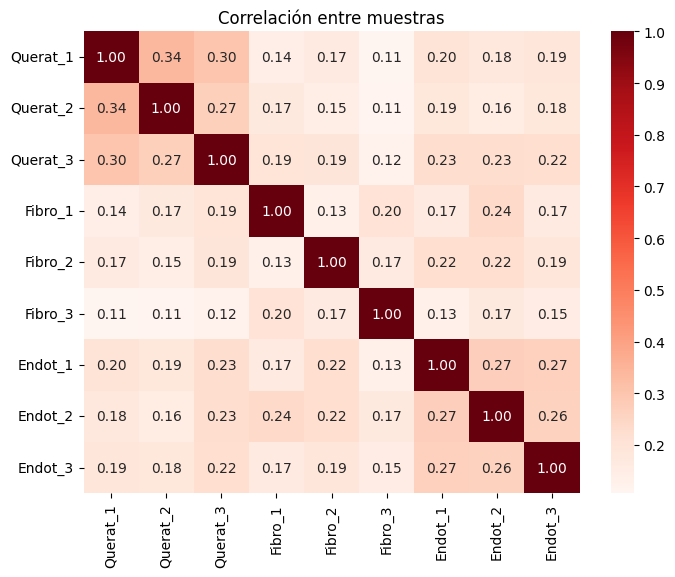

In [19]:
import seaborn as sns

# Correlación entre las 9 muestras (usando todos los genes)
correlacion = datos_limpios.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='Reds')
plt.title('Correlación entre muestras')
plt.show()

In [20]:
# Correlación promedio entre réplicas del mismo tipo celular y entre tipos distintos
tipo_celular = ['Queratinocitos'] * 3 + ['Fibroblastos'] * 3 + ['Endotelio'] * 3
tipos = pd.Series(tipo_celular, index=column_names)

for tipo in ['Queratinocitos', 'Fibroblastos', 'Endotelio']:
    m = tipos[tipos == tipo].index
    valores = correlacion.loc[m, m].values[np.triu_indices(3, k=1)]
    print(f"{tipo}: correlación entre sus réplicas = {valores.mean():.2f}")

entre = [correlacion.loc[a, b] for a in column_names for b in column_names if tipos[a] != tipos[b]]
print(f"Entre tipos celulares distintos = {np.mean(entre):.2f}")

Queratinocitos: correlación entre sus réplicas = 0.30
Fibroblastos: correlación entre sus réplicas = 0.17
Endotelio: correlación entre sus réplicas = 0.27
Entre tipos celulares distintos = 0.18


**¿Las réplicas se parecen entre sí?**

Las correlaciones son bajas en general (entre 0,11 y 0,34), porque la mayoría de los genes no cambia y su log ratio es casi todo ruido. Igual si se ve una diferencia:

- **Queratinocitos: 0,30** entre sus réplicas, el valor más alto.
- **Endotelio: 0,27.**
- **Fibroblastos: 0,17**, prácticamente igual que entre tipos celulares distintos (0,18).

O sea que los queratinocitos y las células endoteliales responden de forma reproducible, pero las 3 réplicas de fibroblastos no se parecen más entre sí que a cualquier otra muestra. **Fibro_3** es la que menos se parece a todas (entre 0,11 y 0,20).

**PCA de las muestras**

In [21]:
# Para el PCA uso los genes con las 9 muestras completas, y cada muestra tiene que ser una fila. Aca no puedo tener valores faltantes ni NaN
x = datos_limpios.dropna().T.values
y = np.array(tipo_celular)

x.shape

(9, 13382)

In [22]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(x)

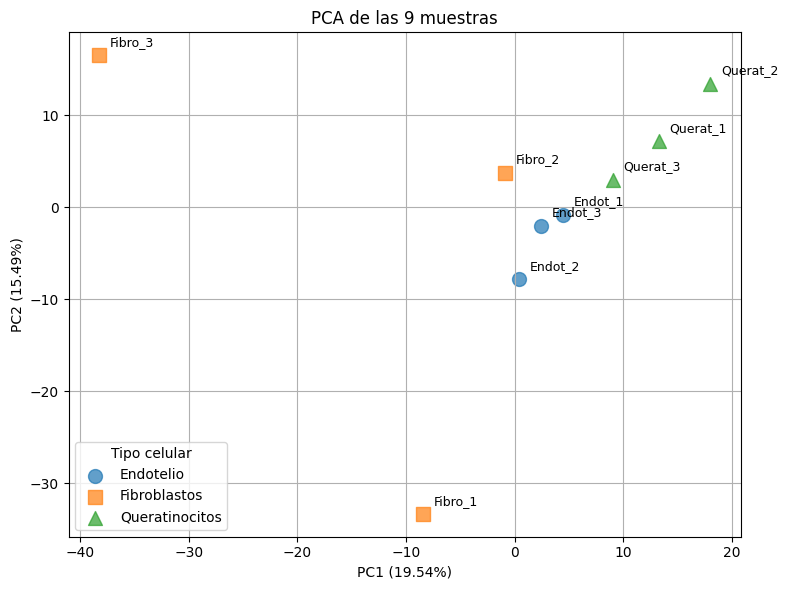

In [23]:
# DataFrame con los resultados del PCA
pca_data = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
pca_data['tipo_celular'] = tipo_celular
pca_data['muestra'] = column_names

# Colores y marcadores
cmap = plt.get_cmap('tab10')
markers = ['o', 's', '^']

plt.figure(figsize=(8, 6))

for i, (tipo, grupo) in enumerate(pca_data.groupby('tipo_celular')):
    plt.scatter(grupo['PC1'], grupo['PC2'],
                color=cmap(i), marker=markers[i],
                label=tipo, alpha=0.7, s=100)

for i in range(len(pca_data)):
    plt.text(pca_data['PC1'][i] + 1, pca_data['PC2'][i] + 1, pca_data['muestra'][i], fontsize=9)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA de las 9 muestras')
plt.legend(title='Tipo celular', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
# Crear un DataFrame con los resultados del PCA
pca_df = pd.DataFrame(data = {
    'standard_deviation': np.sqrt(pca.explained_variance_),
    'proportion_of_variance': pca.explained_variance_ratio_,
    'cumulative_proportion': np.cumsum(pca.explained_variance_ratio_)
})

# Añadir una columna para los componentes principales
pca_df.index = [f'PC{i}' for i in range(1, len(pca_df) + 1)]
pca_df.index.name = 'component'

print("Resumen de PCA:")
print(pca_df)
print("\n")

Resumen de PCA:
           standard_deviation  proportion_of_variance  cumulative_proportion
component                                                                   
PC1              1.638087e+01            1.953809e-01               0.195381
PC2              1.458731e+01            1.549383e-01               0.350319
PC3              1.419410e+01            1.466981e-01               0.497017
PC4              1.240244e+01            1.120012e-01               0.609018
PC5              1.204219e+01            1.055892e-01               0.714608
PC6              1.160148e+01            9.800209e-02               0.812610
PC7              1.140796e+01            9.475992e-02               0.907370
PC8              1.127905e+01            9.263034e-02               1.000000
PC9              2.277993e-14            3.778447e-31               1.000000




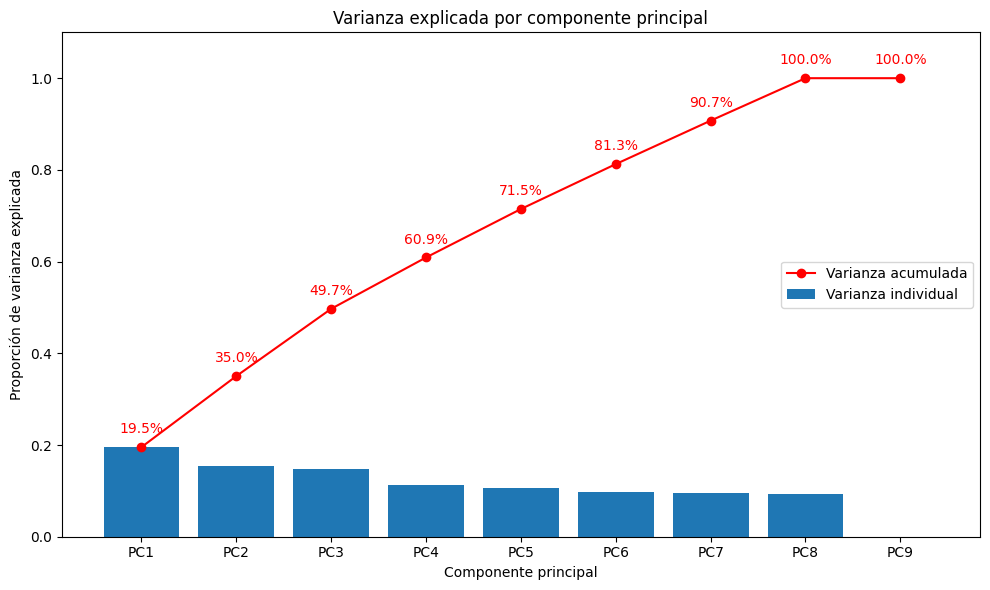

In [25]:
var = pca.explained_variance_ratio_
acum = np.cumsum(var)
pcs = np.arange(1, len(var) + 1)

plt.figure(figsize=(10, 6))
plt.bar(pcs, var, label='Varianza individual')
plt.plot(pcs, acum, marker='o', color='red', label='Varianza acumulada')

# Etiquetar el % acumulado sobre cada punto
for pc, a in zip(pcs, acum):
    plt.text(pc, a + 0.03, f'{a:.1%}', ha='center', color='red')

plt.xticks(pcs, [f'PC{i}' for i in pcs])
plt.ylim(0, 1.1)
plt.xlabel('Componente principal')
plt.ylabel('Proporción de varianza explicada')
plt.title('Varianza explicada por componente principal')
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

**¿Cuánta varianza explican PC1 + PC2? ¿Las réplicas quedan juntas?**

PC1 explica el **19,5 %** y PC2 el **15,5 %**: entre los dos, solo el **35 %**. Es mucho menos que en el Mini-Proyecto 2 (77 %), y las componentes 3 a 8 explican cada una entre 9 y 15 %, o sea que la varianza está muy repartida y no hay una estructura que domine.

En el gráfico:
- Los **queratinocitos** quedan juntos en un extremo (PC1 positivo), y el **endotelio** queda agrupado en el centro.
- Los **fibroblastos están muy dispersos**: **Fibro_3** queda sola a la izquierda (PC1 = -38) y **Fibro_1** sola abajo (PC2 = -33). Son las dos muestras que más "tiran" de las componentes.

In [26]:
# Obtener los vectores de carga (loadings): acá cada variable es un gen
genes_pca = datos_limpios.dropna().index
loadings = pca.components_.T

# Crear un DataFrame con los loadings de PC1 y PC2
loadings_df = pd.DataFrame(loadings[:, :2], columns=['PC1', 'PC2'], index=genes_pca)

print("Vectores de carga (Loadings) de los 10 genes con más peso en PC1:")
print(loadings_df.loc[loadings_df['PC1'].abs().sort_values(ascending=False).head(10).index])

Vectores de carga (Loadings) de los 10 genes con más peso en PC1:
                  PC1       PC2
GENE_SYMBOL                    
IL1B         0.125537 -0.036911
CXCL8        0.112469 -0.064176
CCL2         0.108054 -0.053286
ERN1         0.105042  0.053106
IL6          0.100136 -0.050848
CXCL2        0.096633 -0.030579
CXCL1        0.093130 -0.050216
LRRC72       0.090591  0.027073
CYP1A1       0.087738  0.010450
BIRC3        0.079873 -0.045120


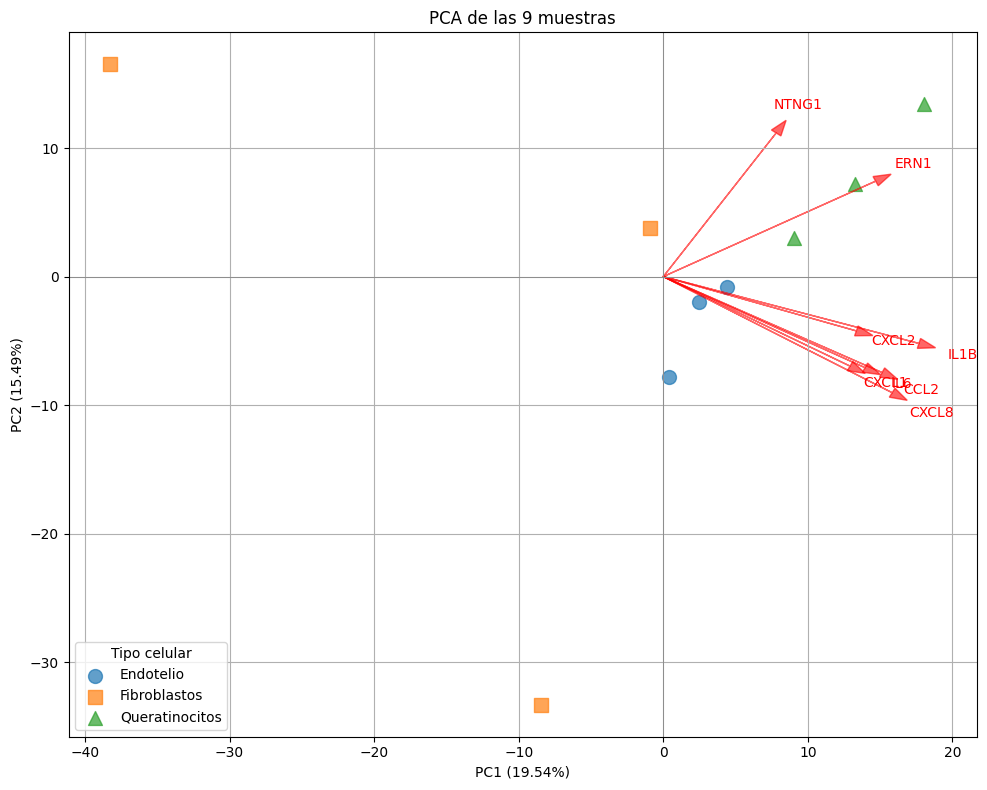

In [27]:
# Biplot: solo los genes que más pesan en el plano PC1-PC2
features = genes_pca

plt.figure(figsize=(10, 8))

# Puntos
for i, (tipo, grupo) in enumerate(pca_data.groupby('tipo_celular')):
    plt.scatter(grupo['PC1'], grupo['PC2'],
                color=cmap(i), marker=markers[i],
                label=tipo, alpha=0.7, s=100)

# Flechas
k = 8
escala = 150   # factor visual para que las flechas se vean junto a los puntos
importancia = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
top = np.argsort(importancia)[::-1][:k]

for j in top:
    lx, ly = loadings[j, 0], loadings[j, 1]
    plt.arrow(0, 0, lx * escala, ly * escala, color='r', alpha=0.6,
              head_width=0.8, length_includes_head=True)
    plt.text(lx * escala * 1.1, ly * escala * 1.1, features[j],
             color='r', ha='center', va='center')

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('PCA de las 9 muestras')
plt.legend(title='Tipo celular', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

In [28]:
# ¿Qué valores tienen los genes con más peso en PC1, en cada muestra?
top_pc1 = loadings_df['PC1'].abs().sort_values(ascending=False).head(10).index
datos_limpios.loc[top_pc1].round(2)

,Querat_1,Querat_2,Querat_3,Fibro_1,Fibro_2,Fibro_3,Endot_1,Endot_2,Endot_3
GENE_SYMBOL,,,,,,,,,
IL1B,0.75,0.74,0.74,-0.63,-0.81,-6.15,-0.43,-0.37,-0.00
CXCL8,0.23,-0.34,-0.25,0.01,-0.71,-6.46,0.00,-0.43,-0.45
CCL2,-0.00,-0.02,-0.06,-0.22,0.01,-6.13,-0.52,-0.29,-0.47
ERN1,1.32,9.79,1.09,1.08,-0.03,-0.43,1.96,0.61,2.13
IL6,0.24,0.33,0.37,0.21,0.42,-5.34,0.04,0.04,0.03
CXCL2,1.06,0.22,0.07,-0.48,0.03,-4.75,0.41,-0.08,0.44
CXCL1,-0.22,-0.17,-0.37,-0.21,-0.11,-5.47,-0.30,-0.35,-0.16
LRRC72,0.70,5.42,0.84,-0.32,-0.04,-1.85,0.97,1.59,0.45
CYP1A1,3.43,3.28,3.17,1.04,-0.39,-1.62,0.24,-0.40,0.27


**¿Qué genes separan a las muestras en PC1?**

La mayoría de los genes con más peso en PC1 son de **inflamación** (IL1B, CXCL8 o IL-8, CCL2, IL6, CXCL2, CXCL1, BIRC3). En el biplot las flechas apuntan hacia los queratinocitos, y uno podría pensar que se activan con la corriente. Pero en la tabla se ve que el cambio grande está **solo en Fibro_3**, con valores de -4 a -6,5 (entre 16 y 90 veces más bajos). En el resto de las muestras los cambios son chicos: por ejemplo, IL1B sube unas 1,7 veces en los queratinocitos (0,75) y baja algo en Fibro_1 y Fibro_2. Las flechas apuntan "para el otro lado" porque lo que define a PC1 es que Fibro_3 tiene valores muy negativos. Como el valor es un cociente estimulado/sham, eso puede pasar si el **cultivo sham de esa réplica estaba inflamado**. Sea por lo que sea, no se repite en las otras réplicas.

La excepción es **CYP1A1**, que también está entre los 10 genes con más peso. En este caso la señal sí es real: sube en las 3 réplicas de queratinocitos (3,43 / 3,28 / 3,17) y casi nada en los demás tipos celulares. Es un primer indicio de la respuesta propia de los queratinocitos.

También aparecen ERN1 y LRRC72, que tienen un valor muy alto solo en Querat_2 (9,8 y 5,4). Son sondas puntuales con errores, pero el resto de Querat_2 se comporta igual que las otras dos réplicas.

## **5- Clustering de las muestras: ¿se recuperan los 3 tipos celulares?**

Con el código de la Práctica 20 agrupo las 9 muestras sin decirle al algoritmo de qué tipo celular es cada una, y después comparo los grupos con el tipo celular real usando la tabla de confusión optimizada y el direct agreement (porcentaje de muestras bien agrupadas). Si la respuesta a la corriente es propia de cada célula, los clusters deberían coincidir con los tipos celulares.

In [29]:
from sklearn.cluster import KMeans
from scipy.spatial import ConvexHull
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder

In [30]:
# Pasar el tipo celular a números
label_encoder = LabelEncoder()
y_true = label_encoder.fit_transform(y)

# Imprimir las correspondencias entre etiquetas originales y valores numéricos
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Correspondencia entre etiquetas originales y valores numéricos:")
print(label_mapping)

Correspondencia entre etiquetas originales y valores numéricos:
{np.str_('Endotelio'): 0, np.str_('Fibroblastos'): 1, np.str_('Queratinocitos'): 2}


**Con método divisivo (K-Means)**

In [31]:
# Aplicar K-Means
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca)

kmeans_labels

array([2, 2, 2, 0, 1, 1, 1, 1, 1], dtype=int32)

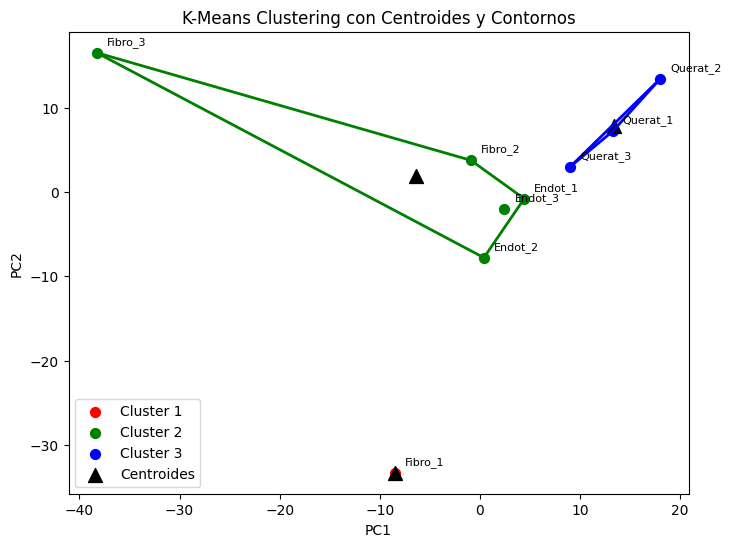

In [32]:
# Obtener los centroides
centroids = kmeans.cluster_centers_

# Visualización de K-Means con centroides y contornos
plt.figure(figsize=(8, 6))
colors = ['red', 'green', 'blue']  # Colores para cada cluster

for i in range(3):  # Para cada cluster
    points = X_pca[kmeans_labels == i]  # Seleccionar puntos del cluster
    plt.scatter(points[:, 0], points[:, 1], c=colors[i], label=f'Cluster {i+1}', s=50)

    # Dibujar el contorno del cluster usando Convex Hull (necesita al menos 3 puntos)
    if len(points) >= 3:
        hull = ConvexHull(points[:, :2])
        for simplex in hull.simplices:
            plt.plot(points[simplex, 0], points[simplex, 1], color=colors[i], lw=2)

# Nombre de cada muestra
for i in range(len(column_names)):
    plt.text(X_pca[i, 0] + 1, X_pca[i, 1] + 1, column_names[i], fontsize=8)

# Dibujar los centroides con un triángulo negro
plt.scatter(centroids[:, 0], centroids[:, 1], marker='^', s=100, c='black', label='Centroides')

plt.title("K-Means Clustering con Centroides y Contornos")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

In [33]:
y_pred = kmeans.labels_  # Clusters predichos por K-means

# Crear la tabla de confusión inicial
cont_table = pd.crosstab(y_pred, y_true, rownames=['Cluster'], colnames=['Clase real'])

# Aplicar algoritmo para encontrar la mejor correspondencia
_, class_match = linear_sum_assignment(-cont_table)

# Optimizar la tabla de confusión para que los clusters coincidan con las clases
optimized_cont_table = cont_table.iloc[:, class_match]

# Renombrar las columnas para que coincidan con las clases reales
optimized_cont_table.columns = [0, 1, 2]

# Imprimir la tabla de confusión optimizada
print("Tabla de confusión optimizada:")
print(optimized_cont_table)
# Calcular el "Direct agreement" o coincidencia directa
matched_labels = [class_match[label] for label in y_pred]  # Etiquetas de clase mapeadas
direct_agreement = accuracy_score(y_true, matched_labels) * 100
print(f"\nDirect agreement: {direct_agreement:.2f}%")

Tabla de confusión optimizada:
         0  1  2
Cluster         
0        1  0  0
1        2  3  0
2        0  0  3

Direct agreement: 77.78%


**¿El K-Means recupera los 3 tipos celulares?**

En parte. El *direct agreement* es **77,78 %** (7 de 9 muestras bien agrupadas):
- Los **3 queratinocitos** forman un cluster solos, perfecto.
- **Fibro_1** queda sola en otro cluster.
- **Fibro_2, Fibro_3 y las 3 células endoteliales** quedan juntas en el tercero.

O sea que los queratinocitos tienen una respuesta a la corriente propia y reconocible, mientras que los fibroblastos no se parecen entre sí.

**Con método jerárquico**

In [34]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.colors as mcolors

# Estrategias de linkage
linkage_methods = ['single', 'complete', 'average']

def plot_dendrogram_with_cut(Z, ax, n_clusters=3, labels=None):
    # Obtener el color_threshold para n clusters
    color_threshold = Z[-n_clusters+1, 2]

    # Dibujar el dendrograma
    dendrogram(Z, ax=ax, color_threshold=color_threshold, above_threshold_color='blue', labels=labels)

    # Agregar línea de corte
    ax.axhline(y=color_threshold, color='gray', linestyle='--')

    ax.set_xlabel('Muestra')
    ax.set_ylabel('Distance')


Tabla de confusión optimizada (single linkage):
         0  1  2
Cluster         
1        3  1  3
2        0  1  0
3        0  1  0
Direct agreement (single linkage): 44.44%

Tabla de confusión optimizada (complete linkage):
         0  1  2
Cluster         
1        3  1  3
2        0  1  0
3        0  1  0
Direct agreement (complete linkage): 44.44%

Tabla de confusión optimizada (average linkage):
         0  1  2
Cluster         
1        3  1  3
2        0  1  0
3        0  1  0
Direct agreement (average linkage): 44.44%


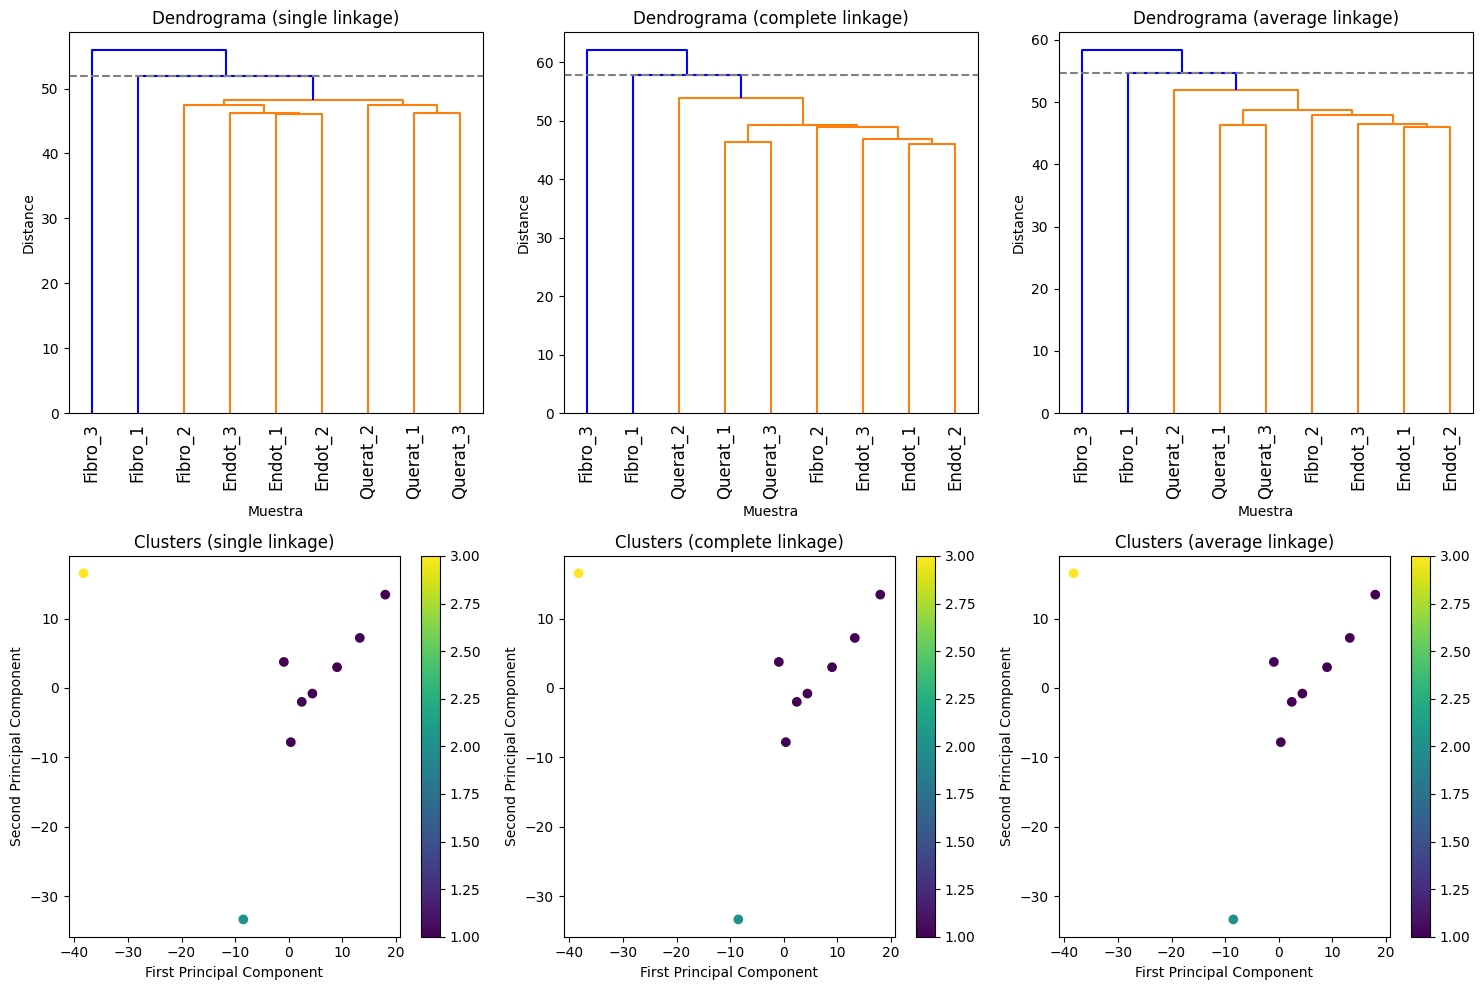

In [35]:
# Crear figura para los dendrogramas y scatter plots
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i, method in enumerate(linkage_methods):
    # Aplicar clustering jerárquico
    Z = linkage(X_pca, method=method)
    y_pred = fcluster(Z, t=3, criterion='maxclust')

    # Graficar el dendrograma con línea de corte y 3 clusters
    axs[0, i].set_title(f'Dendrograma ({method} linkage)')
    plot_dendrogram_with_cut(Z, axs[0, i], n_clusters=3, labels=column_names)
    axs[0, i].tick_params(axis='x', rotation=90)

    # Scatter plot de los primeros dos componentes principales
    scatter = axs[1, i].scatter(X_pca[:, 0], X_pca[:, 1], c=y_pred, cmap='viridis')
    axs[1, i].set_title(f'Clusters ({method} linkage)')
    axs[1, i].set_xlabel('First Principal Component')
    axs[1, i].set_ylabel('Second Principal Component')
    plt.colorbar(scatter, ax=axs[1, i])

    # Calcular y mostrar métricas
    cont_table = pd.crosstab(y_pred, y_true, rownames=['Cluster'], colnames=['Clase real'])
    _, class_match = linear_sum_assignment(-cont_table)
    optimized_cont_table = cont_table.iloc[:, class_match]
    optimized_cont_table.columns = [0, 1, 2]

    print(f"\nTabla de confusión optimizada ({method} linkage):")
    print(optimized_cont_table)

    matched_labels = [class_match[label - 1] for label in y_pred]
    direct_agreement = accuracy_score(y_true, matched_labels) * 100
    print(f"Direct agreement ({method} linkage): {direct_agreement:.2f}%")

plt.tight_layout()
plt.show()

**¿Y el método jerárquico?**

Con las 3 estrategias (single, complete y average) el *direct agreement* es solo **44,44 %**, porque al cortar en 3 clusters, **Fibro_3 y Fibro_1 quedan cada una sola** (son las muestras más alejadas de todas) y las otras 7 quedan juntas.

Mirando el dendrograma de *single linkage* por debajo de la línea de corte, igual se ve que los 3 queratinocitos se unen entre sí y las 3 células endoteliales también. El problema son los fibroblastos.

**Decisión:** saco **Fibro_3** del análisis de los genes. Es un outlier: es la que menos correlaciona en promedio con el resto (alrededor de 0,15), queda sola en el PCA y en el clustering jerárquico, y tiene una señal de inflamación que no aparece en ninguna otra muestra. Fibro_1 también es rara, pero si la sacara me quedaría con una sola réplica de fibroblastos.

Hay que tener en cuenta que las dos réplicas que quedan, Fibro_1 y Fibro_2, son justamente las que menos se parecen entre sí (correlación 0,13, la más baja dentro de un mismo tipo celular). Por eso los resultados de fibroblastos son los menos confiables del trabajo.

In [36]:
# Grupos para el análisis, sin la réplica Fibro_3
grupos = {'Queratinocitos': ['Querat_1', 'Querat_2', 'Querat_3'],
          'Fibroblastos':   ['Fibro_1', 'Fibro_2'],
          'Endotelio':      ['Endot_1', 'Endot_2', 'Endot_3']}

## **6- ¿Se puede entrenar un clasificador? (Random Forest)**

 ¿se puede predecir el tipo celular de una muestra a partir de su respuesta a la corriente? Las características (x) son los genes y la etiqueta (y) es el tipo celular.

In [37]:
from sklearn.ensemble import RandomForestClassifier

# Definir y entrenar el modelo Random Forest con OOB (Out-Of-Bag)
rf_model = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)
rf_model.fit(x, y)

RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)

In [38]:
# Imprimir un resumen del modelo
print("Resumen del modelo Random Forest:")
print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {rf_model.classes_}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.5556
Número de características: 13382
Clases: ['Endotelio' 'Fibroblastos' 'Queratinocitos']


In [39]:
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir probabilidades a etiquetas de clase (la clase con la probabilidad más alta)
oob_predicted_labels = rf_model.classes_[np.argmax(oob_predictions, axis=1)]

# Crear la matriz de confusión usando las etiquetas reales y las predicciones OOB
conf_matrix = confusion_matrix(y, oob_predicted_labels, labels=rf_model.classes_)

# Convertir la matriz de confusión a un DataFrame para un formato legible
conf_matrix_df = pd.DataFrame(conf_matrix, index=rf_model.classes_, columns=rf_model.classes_)

# Calcular el error de clase para cada clase
class_error = 1 - np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

# Imprimir la matriz de confusión con nombres de filas y columnas
print("Matriz de Confusión OOB con Nombres de Clases:")
print(conf_matrix_df)

# Imprimir el error de clase para cada clase
print("\nError de Clase (Class Error) por clase:")
for cls, error in zip(rf_model.classes_, class_error):
    print(f"Clase {cls}: Error de Clase {error:.4f}")

Matriz de Confusión OOB con Nombres de Clases:
                Endotelio  Fibroblastos  Queratinocitos
Endotelio               1             0               2
Fibroblastos            1             1               1
Queratinocitos          0             0               3

Error de Clase (Class Error) por clase:
Clase Endotelio: Error de Clase 0.6667
Clase Fibroblastos: Error de Clase 0.6667
Clase Queratinocitos: Error de Clase 0.0000


In [40]:
# Las 10 características (genes) más importantes
feature_importance = pd.Series(rf_model.feature_importances_, index=genes_pca)
print(feature_importance.sort_values(ascending=False).head(10))

GENE_SYMBOL
GPR126      0.002415
PLCB3       0.002083
OR5L2       0.001918
DUSP5       0.001918
RABL2A      0.001915
SUV420H1    0.001908
ACER3       0.001880
HPS6        0.001715
MYL6B       0.001708
TATDN3      0.001708
dtype: float64


**¿Funciona el clasificador?**

No. La precisión OOB es **0,56**: acierta 5 de 9 muestras. Por azar, con 3 clases, se acertaría alrededor de 1 de cada 3 (0,33), así que es apenas mejor que adivinar. Reconoce bien a los **3 queratinocitos** (error 0), pero se equivoca en 2 de 3 endoteliales y en 2 de 3 fibroblastos.

Además, la importancia de los genes es bajísima (0,002 el más importante) y casi todos son genes sin relación clara con la cicatrización. Una excepción es **DUSP5**, que aparece entre los 10 más importantes y es uno de los genes de la vía MAPK-ERK que el paper reporta en queratinocitos. Pero con importancias tan bajas e iguales entre sí, no se puede sacar ninguna conclusión: con 13.382 características y solo 9 muestras, el modelo no tiene de dónde aprender. Además, con 9 muestras cada árbol deja afuera unas 3 para el OOB, así que esa precisión varía muchísimo de un modelo a otro.

Esto confirma lo que esperaba: **con 9 muestras no se puede entrenar un clasificador**. Cualquier modelo se aprendería las muestras de memoria y no quedarían muestras para hacer un test. Por eso no sigo con árbol de decisión, SVM ni redes neuronales. En el resto del trabajo uso métodos **no supervisados** (PCA y clustering), que no necesitan muchas muestras con etiqueta, y para los genes, que sí son miles, el clustering.

## **7- ¿Qué genes cambian con la corriente?**

Ahora la pregunta es gen por gen. Con solo 3 réplicas (2 en fibroblastos), un test estadístico tiene muy poca potencia, así que uso como criterio principal un **criterio de cambio consistente**, que es lo que se hace habitualmente en microarrays de dos colores con pocas réplicas. Además, como respaldo, calculo un test estadístico (lo explico después de la tabla).

Un gen **sube** con la corriente si:
- la **mediana** de sus réplicas es **≥ 1** (al menos el doble de expresión), y
- **todas las réplicas son ≥ 0,5** (cada réplica por lo menos 1,4 veces).

Y **baja** si la mediana es ≤ -1 y todas las réplicas son ≤ -0,5.

Uso la **mediana** y no el promedio porque algunas réplicas tienen valores extremos en sondas puntuales (por ejemplo LRRC72 en queratinocitos: 0,70 / 5,42 / 0,84). Con el promedio daría 2,3 y parecería que sube mucho; con la mediana da 0,84, que es lo que muestran 2 de las 3 réplicas.

Además pido que el gen tenga **al menos 2 réplicas válidas** en ese tipo celular.

In [41]:
from scipy import stats
from statsmodels.stats.multitest import multipletests

resultados = {}

for tipo, columnas in grupos.items():
    valores = datos_limpios[columnas]

    # Solo genes con al menos 2 réplicas válidas en este tipo celular
    valores = valores[valores.notna().sum(axis=1) >= 2]

    tabla = pd.DataFrame({'log2FC': valores.median(axis=1),
                          'minimo': valores.min(axis=1),
                          'maximo': valores.max(axis=1)})

    # t-test de una muestra: H0 = el log2FC promedio es 0 (el gen no cambia)
    n = valores.notna().sum(axis=1)
    media = valores.mean(axis=1)
    desvio = valores.std(axis=1, ddof=1)
    t = media / (desvio / np.sqrt(n))
    tabla['p'] = 2 * stats.t.sf(np.abs(t), df=n - 1)

    # Corrección por comparaciones múltiples (Benjamini-Hochberg)
    tabla['FDR'] = multipletests(tabla['p'].fillna(1), method='fdr_bh')[1]

    # Clasificar cada gen (criterio de cambio consistente)
    tabla['cambio'] = 'No cambia'
    tabla.loc[(tabla['log2FC'] >= 1) & (tabla['minimo'] >= 0.5), 'cambio'] = 'Sube'
    tabla.loc[(tabla['log2FC'] <= -1) & (tabla['maximo'] <= -0.5), 'cambio'] = 'Baja'

    resultados[tipo] = tabla.sort_values('log2FC', ascending=False)

    print(tipo, "- genes analizados:", len(tabla))
    print(tabla['cambio'].value_counts())
    print("Genes con p < 0,05:", (tabla['p'] < 0.05).sum())
    print("Genes con FDR < 0,05:", (tabla['FDR'] < 0.05).sum())
    print("Genes del criterio que además tienen p < 0,05:",
          ((tabla['cambio'] != 'No cambia') & (tabla['p'] < 0.05)).sum())
    print()

Queratinocitos - genes analizados: 15582
cambio
No cambia    15364
Baja           161
Sube            57
Name: count, dtype: int64
Genes con p < 0,05: 3387
Genes con FDR < 0,05: 5
Genes del criterio que además tienen p < 0,05: 116

Fibroblastos - genes analizados: 15328
cambio
No cambia    15099
Sube           124
Baja           105
Name: count, dtype: int64
Genes con p < 0,05: 926
Genes con FDR < 0,05: 63
Genes del criterio que además tienen p < 0,05: 49

Endotelio - genes analizados: 15729
cambio
No cambia    15495
Baja           173
Sube            61
Name: count, dtype: int64
Genes con p < 0,05: 3486
Genes con FDR < 0,05: 3
Genes del criterio que además tienen p < 0,05: 98



**¿Cuántos genes cambian en cada tipo celular?**

| | Genes analizados | Suben | Bajan |
|---|---|---|---|
| Queratinocitos | 15.582 | 57 | 161 |
| Fibroblastos | 15.328 | 124 | 105 |
| Endotelio | 15.729 | 61 | 173 |

Los 3 tipos celulares dan números parecidos (entre 218 y 234 genes). Contar genes no alcanza para decir qué célula responde más. Lo que sí se ve en el gráfico de réplica contra réplica es que en los **queratinocitos** los genes que suben más (CYP1A1 y CYP1B1) quedan muy lejos de la nube y en la diagonal, o sea que cambian mucho y **lo mismo en las dos réplicas**. En fibroblastos, en cambio, los genes marcados están pegados a la nube.

**¿Qué dice el test estadístico?** Con un t-test de una muestra (H0: log2FC = 0) y la corrección de Benjamini-Hochberg por comparaciones múltiples:

| | p < 0,05 | FDR < 0,05 | Genes del criterio con p < 0,05 |
|---|---|---|---|
| Queratinocitos | 3.387 | 5 | 116 de 218 |
| Fibroblastos | 926 | 63 | 49 de 229 |
| Endotelio | 3.486 | 3 | 98 de 234 |

Después de corregir por comparaciones múltiples casi ningún gen es significativo. Ni siquiera CYP1A1, el cambio más grande y consistente del experimento, pasa el umbral (FDR = 0,12). Es lo esperable con 2 o 3 réplicas y más de 15.000 tests.

El test también muestra sus propios problemas con tan pocas réplicas:
- **Fibroblastos tienen más genes con FDR < 0,05 (63) que los otros tipos, aunque son los menos confiables.** Con solo 2 réplicas, si los dos valores casi coinciden el desvío da casi 0 y el p sale artificialmente chico.
- **Más del 20 % de los genes tiene p < 0,05** en queratinocitos y endotelio, mucho más que el 5 % esperable por azar. Muchos son cambios muy chicos pero parecidos en las 3 réplicas: estadísticamente "significativos", pero sin importancia biológica.

Por eso el test queda como respaldo y el criterio principal sigue siendo la consistencia entre réplicas, que además exige un cambio de al menos el doble.

In [42]:
# Los 15 genes que más suben en queratinocitos
resultados['Queratinocitos'].head(15).round(2)

,log2FC,minimo,maximo,p,FDR,cambio
GENE_SYMBOL,,,,,,
ZKSCAN7,4.57,0.28,8.86,0.48,0.66,No cambia
URAD,4.45,0.39,8.52,0.47,0.65,No cambia
CYP1A1,3.28,3.17,3.43,0.00,0.12,Sube
CYP1B1,2.31,2.28,2.40,0.00,0.11,Sube
HFM1,1.89,0.03,3.75,0.49,0.67,No cambia
LRRN4CL,1.79,-0.62,1.80,0.35,0.55,No cambia
LURAP1,1.75,-0.13,2.27,0.22,0.43,No cambia
C9orf92,1.71,0.64,1.86,0.07,0.25,Sube
FGR,1.68,0.70,1.94,0.06,0.25,Sube


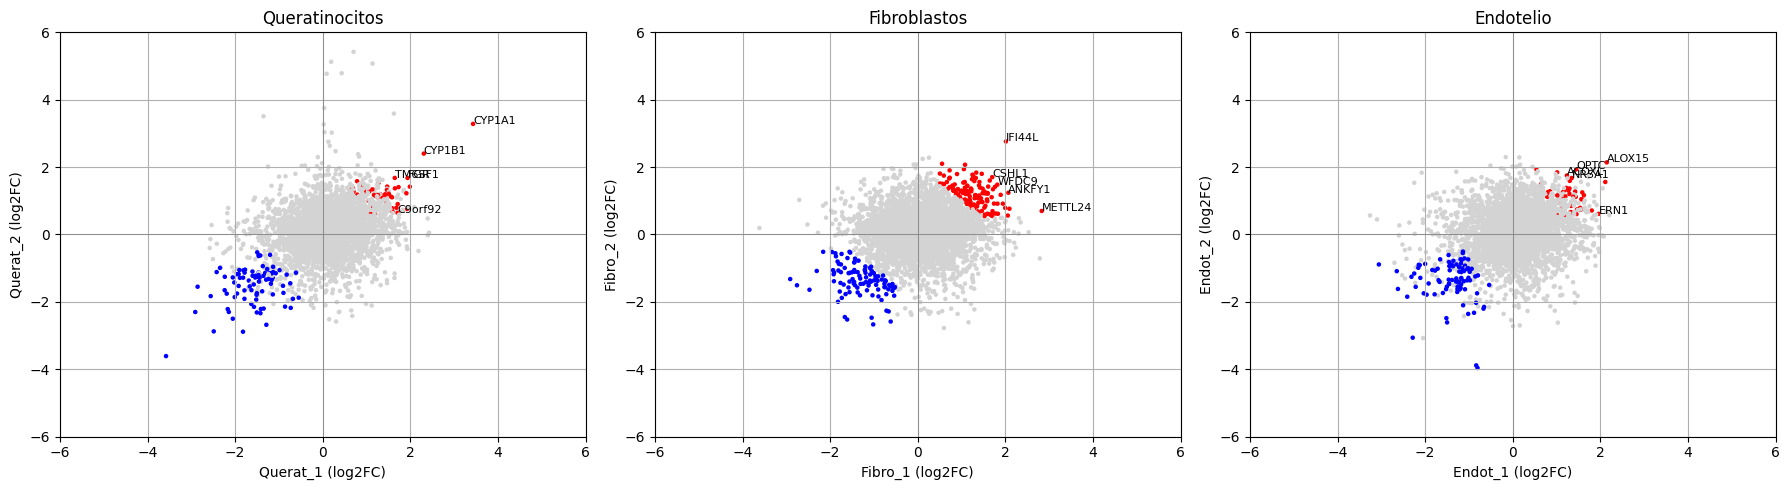

In [43]:
# Réplica 1 vs. réplica 2: si un gen cambia de verdad, cambia en las dos réplicas
colores = {'Sube': 'red', 'Baja': 'blue', 'No cambia': 'lightgrey'}

plt.figure(figsize=(18, 5))

for i, (tipo, columnas) in enumerate(grupos.items()):
    tabla = resultados[tipo]
    valores = datos_limpios.loc[tabla.index, columnas]

    plt.subplot(1, 3, i + 1)
    plt.scatter(valores[columnas[0]], valores[columnas[1]], c=tabla['cambio'].map(colores), s=5)
    plt.axhline(0, color='grey', lw=0.5)
    plt.axvline(0, color='grey', lw=0.5)

    # Poner el nombre de los 5 genes que más suben
    for gen in tabla[tabla['cambio'] == 'Sube'].head(5).index:
        plt.text(valores.loc[gen, columnas[0]], valores.loc[gen, columnas[1]], gen, fontsize=8)

    plt.title(tipo)
    plt.xlabel(columnas[0] + ' (log2FC)')
    plt.ylabel(columnas[1] + ' (log2FC)')
    plt.xlim(-6, 6)
    plt.ylim(-6, 6)
    plt.grid(True)

plt.tight_layout()
plt.show()

**Control: ¿aparecen los genes que reportó el paper?**

Aoki et al. (2019) encontraron en los queratinocitos que suben CYP1A1, CYP1B1, HMOX1, EREG, DUSP5 y SLC7A11, y que bajan DOCK8, ABCC6 y CYP26A1. Si mi análisis está bien, deberían aparecer con el mismo signo.

In [44]:
genes_paper = {'CYP1A1': 'Sube', 'CYP1B1': 'Sube', 'HMOX1': 'Sube', 'EREG': 'Sube', 'DUSP5': 'Sube',
               'SLC7A11': 'Sube', 'DOCK8': 'Baja', 'ABCC6': 'Baja', 'CYP26A1': 'Baja'}

control = pd.DataFrame({'paper': genes_paper})
control = control.join(resultados['Queratinocitos'][['log2FC', 'p', 'cambio']])
control = control.join(datos_limpios[grupos['Queratinocitos']])

control.round(2)

,paper,log2FC,p,cambio,Querat_1,Querat_2,Querat_3
CYP1A1,Sube,3.28,0.00,Sube,3.43,3.28,3.17
CYP1B1,Sube,2.31,0.00,Sube,2.31,2.40,2.28
HMOX1,Sube,1.64,0.01,Sube,1.99,1.42,1.64
EREG,Sube,1.31,0.00,Sube,1.31,1.19,1.38
DUSP5,Sube,1.17,0.01,Sube,1.17,1.17,0.81
SLC7A11,Sube,1.08,0.01,Sube,1.15,0.82,1.08
DOCK8,Baja,-1.12,0.00,Baja,-1.13,-1.12,-1.10
ABCC6,Baja,-0.31,0.11,No cambia,-0.22,-0.70,-0.31
CYP26A1,Baja,-0.98,0.01,No cambia,-1.28,-0.90,-0.98


**¿Coincide con el paper?**

**Sí, en 7 de los 9 genes.** Los 6 que el paper dice que suben (CYP1A1, CYP1B1, HMOX1, EREG, DUSP5, SLC7A11) suben en las 3 réplicas, y DOCK8 baja en las 3. CYP26A1 baja en las 3 réplicas pero queda justo en el borde del criterio (mediana -0,98), y ABCC6 baja pero menos del doble.

Esto es importante porque **valida todo el análisis**: la orientación de los colores (Cy5 = estimulado), el orden de las columnas, el paso de log10 a log2 y la limpieza.

Lo más llamativo es lo consistente que es CYP1A1: 3,43; 3,28 y 3,17 en las tres réplicas, o sea unas **10 veces más expresado** con la corriente.

En el t-test, **los 7 genes que coinciden con el paper tienen p < 0,05** en queratinocitos (entre 0,001 y 0,01), aunque ninguno pasa la corrección FDR. CYP26A1 también tiene p = 0,01: baja de forma consistente, solo que queda justo en el borde del criterio de 2 veces.

In [45]:
# ¿Cuántos genes cambian en los 3 tipos celulares y cuántos en uno solo?
cambian = {tipo: set(tabla[tabla['cambio'] != 'No cambia'].index) for tipo, tabla in resultados.items()}

q, f, e = cambian['Queratinocitos'], cambian['Fibroblastos'], cambian['Endotelio']

print("Solo en queratinocitos:", len(q - f - e))
print("Solo en fibroblastos:", len(f - q - e))
print("Solo en endotelio:", len(e - q - f))
print("En los 3 tipos celulares:", len(q & f & e))
print("Genes que cambian en al menos uno:", len(q | f | e))
print()
print("Genes que cambian en los 3:", sorted(q & f & e))

Solo en queratinocitos: 180
Solo en fibroblastos: 195
Solo en endotelio: 187
En los 3 tipos celulares: 11
Genes que cambian en al menos uno: 616

Genes que cambian en los 3: ['ACTL8', 'C4orf19', 'CLEC2L', 'CLEC4C', 'IRF4', 'KRTAP9-9', 'LIN28A', 'PRAMEF12', 'PRAMEF4', 'RALYL', 'TMPRSS12']


**¿Hay una respuesta común a la corriente o cada célula responde distinto?**

La respuesta es **casi toda específica de cada tipo celular**: de los 616 genes que cambian en al menos uno, 180 son solo de queratinocitos, 195 solo de fibroblastos y 187 solo de endotelio. Solo **11 genes** cambian en los 3.

Esos 11 genes en común me parecen sospechosos: ACTL8, LIN28A, IRF4, PRAMEF4, PRAMEF12, CLEC4C... son genes de testículo, de células madre embrionarias o de células inmunes, que no deberían expresarse en células de la piel, y cambian igual en los 3 tipos celulares. En este experimento el ARN estimulado siempre se marcó con Cy5 y el sham con Cy3, sin intercambiar los colores (*dye swap*). Algunas sondas captan un colorante mejor que el otro, y eso aparece como un "cambio" idéntico en todos los chips. Lo más probable es que estos genes sean ese **artefacto del colorante** y no una respuesta real a la corriente.

## **8- Clustering de los genes que cambian**

Ahora miro la tabla al revés: cada **gen** es una observación, descripta por cuánto cambió en cada tipo celular (3 características: la mediana del log2FC en queratinocitos, fibroblastos y endotelio). Así tengo cientos de observaciones y las puedo agrupar en clusters.

**¿Cuántos clusters?** Si cada célula responde a su manera, esperaría **6 patrones**: que el gen suba o baje en cada uno de los 3 tipos celulares. Por eso uso k = 6.

De los 616 genes que cambian en al menos un tipo celular, para el clustering uso solo los que tienen un valor (la mediana de sus réplicas) en los **3 tipos celulares**. Si a un gen le falta el valor en un tipo celular, no se puede ubicar en el espacio de 3 dimensiones, y el K-Means no admite valores faltantes. Por eso trabajo con un número menor de genes.

Aplico un PCA antes, pero solo para poder **graficar** los 3 valores en 2D. Como no escalo los datos, el PCA solo rota los puntos y no cambia las distancias entre ellos, así que el K-Means daría los mismos clusters con o sin PCA.

In [46]:
genes_que_cambian = sorted(q | f | e)

perfil = pd.DataFrame({tipo: resultados[tipo]['log2FC'] for tipo in grupos}).loc[genes_que_cambian]
perfil = perfil.dropna()   # genes medidos en los 3 tipos celulares

X_genes = perfil.values
print("Genes para el clustering:", len(perfil))
perfil

Genes para el clustering: 361


,Queratinocitos,Fibroblastos,Endotelio
GENE_SYMBOL,,,
ABCB1,-1.490715,0.152809,-0.114607
ABCG4,0.996578,1.034781,-0.049829
ACOXL,0.627844,0.370395,1.750656
ACTA1,0.202638,1.391888,1.059695
ACTL7A,0.827160,1.222470,0.222569
...,...,...,...
ZNF154,-1.190911,0.421885,0.275720
ZNF674,0.279042,1.124473,0.043185
ZNF681,0.451782,1.511477,0.212603


In [47]:
# Aplicar PCA (para poder graficar las 3 características en 2D)
pca_genes = PCA()
X_genes_pca = pca_genes.fit_transform(X_genes)

# Aplicar K-Means
kmeans = KMeans(n_clusters=6, random_state=42)
kmeans_labels = kmeans.fit_predict(X_genes_pca)

# Obtener los centroides
centroids = kmeans.cluster_centers_

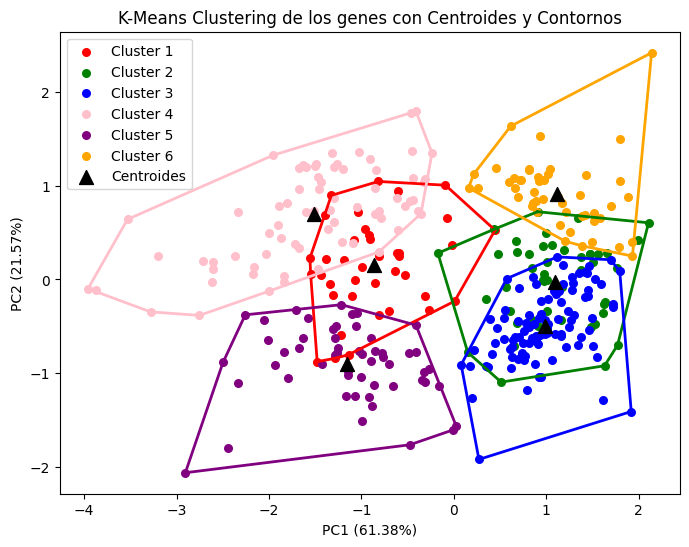

In [48]:
# Visualización de K-Means con centroides y contornos
plt.figure(figsize=(8, 6))
colors = ['red', 'green', 'blue', 'pink', 'purple', 'orange']  # Colores para cada cluster

for i in range(6):  # Para cada cluster
    points = X_genes_pca[kmeans_labels == i]  # Seleccionar puntos del cluster
    plt.scatter(points[:, 0], points[:, 1], c=colors[i], label=f'Cluster {i+1}', s=30)

    # Dibujar el contorno del cluster usando Convex Hull
    hull = ConvexHull(points[:, :2])
    for simplex in hull.simplices:
        plt.plot(points[simplex, 0], points[simplex, 1], color=colors[i], lw=2)

# Dibujar los centroides con un triángulo negro
plt.scatter(centroids[:, 0], centroids[:, 1], marker='^', s=100, c='black', label='Centroides')

plt.title("K-Means Clustering de los genes con Centroides y Contornos")
plt.xlabel(f'PC1 ({pca_genes.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca_genes.explained_variance_ratio_[1]:.2%})')
plt.legend()
plt.show()

In [49]:
# Promedio de cada cluster en cada tipo celular y cuántos genes tiene
perfil['cluster'] = kmeans_labels + 1

resumen = perfil.groupby('cluster')[list(grupos)].mean().round(2)
resumen['n_genes'] = perfil['cluster'].value_counts().sort_index()

resumen

,Queratinocitos,Fibroblastos,Endotelio,n_genes
cluster,,,,
1,-0.14,-0.01,-1.31,39
2,0.30,0.38,1.33,48
3,0.25,1.25,0.23,100
4,-0.42,-1.35,-0.72,72
5,-1.50,-0.18,-0.25,54
6,1.34,0.30,0.41,48


**¿Qué patrón tiene cada cluster?**

Los 6 clusters corresponden a los 6 patrones que esperaba, aunque uno de ellos (el 4) no es del todo limpio:

| Cluster | Patrón | Genes |
|---|---|---|
| 6 | **Suben solo en queratinocitos** (1,34) | 48 |
| 5 | **Bajan solo en queratinocitos** (-1,50) | 54 |
| 3 | **Suben solo en fibroblastos** (1,25) | 100 |
| 4 | **Bajan sobre todo en fibroblastos** (-1,35) | 72 |
| 2 | **Suben solo en endotelio** (1,33) | 48 |
| 1 | **Bajan solo en endotelio** (-1,31) | 39 |

Esto confirma que **cada célula responde a su manera**. En el heatmap se ven claramente los bloques rojos y azules de cada tipo celular.

En el gráfico de K-Means los clusters se pisan un poco porque los agrupé con las 3 características y el gráfico muestra solo 2 componentes (PC1 + PC2 explican el 83 %).

El **cluster 6** es el más interesante: ahí quedaron CYP1A1, CYP1B1, HMOX1, DUSP5 y SLC7A11, la respuesta propia de los queratinocitos que reporta el paper, y DOCK8 quedó en el cluster 5. (EREG e IL1A no entran al clustering porque no se midieron bien en los 3 tipos celulares.)



In [50]:
# ¿En qué cluster quedaron los genes del paper?
perfil.reindex(['CYP1A1', 'CYP1B1', 'HMOX1', 'DUSP5', 'SLC7A11', 'EREG', 'IL1A', 'DOCK8', 'CYP26A1']).round(2)

,Queratinocitos,Fibroblastos,Endotelio,cluster
GENE_SYMBOL,,,,
CYP1A1,3.28,0.33,0.24,6.0
CYP1B1,2.31,0.57,0.35,6.0
HMOX1,1.64,-0.31,0.45,6.0
DUSP5,1.17,-0.14,0.23,6.0
SLC7A11,1.08,0.09,0.50,6.0
EREG,NaN,NaN,NaN,NaN
IL1A,NaN,NaN,NaN,NaN
DOCK8,-1.12,-0.74,-0.15,5.0
CYP26A1,NaN,NaN,NaN,NaN


In [51]:
# ¿En qué cluster quedaron los 11 genes que cambian en los 3 tipos celulares?
comunes = sorted(q & f & e)
perfil.reindex(comunes).round(2)

,Queratinocitos,Fibroblastos,Endotelio,cluster
GENE_SYMBOL,,,,
ACTL8,-2.30,-2.12,-2.37,4
C4orf19,-1.42,-1.65,-1.34,4
CLEC2L,-1.14,-1.23,-1.29,4
CLEC4C,-2.23,-1.76,-1.61,4
IRF4,-1.50,-1.71,-2.27,4
KRTAP9-9,-1.32,-1.35,-1.78,4
LIN28A,-2.30,-2.13,-2.21,4
PRAMEF12,-1.81,-1.16,-1.75,4
PRAMEF4,-1.33,-2.06,-2.66,4


**¿Dónde quedaron los genes del posible artefacto del colorante?** Los 11 genes que cambian en los 3 tipos celulares entran al clustering y **quedan todos en el cluster 4**, con valores muy parecidos en los 3 tipos celulares (entre -1 y -2,7). Esto explica por qué el cluster 4 es el único que no es un patrón "limpio": además de bajar en fibroblastos (-1,35), baja algo en endotelio (-0,72) y en queratinocitos (-0,42), justamente lo que se espera de genes que bajan en todos los chips por el colorante. Son 11 de los 72 genes del cluster.

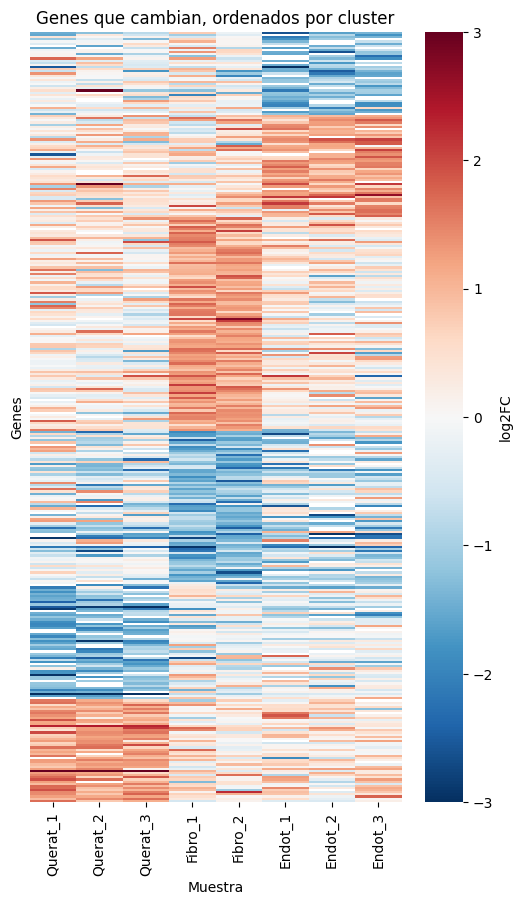

In [52]:
# Heatmap: genes ordenados por cluster, con las 8 muestras usadas
muestras_usadas = grupos['Queratinocitos'] + grupos['Fibroblastos'] + grupos['Endotelio']
orden = perfil.sort_values('cluster').index

plt.figure(figsize=(6, 10))
sns.heatmap(datos_limpios.loc[orden, muestras_usadas], cmap='RdBu_r', vmin=-3, vmax=3,
            yticklabels=False, cbar_kws={'label': 'log2FC'})
plt.title('Genes que cambian, ordenados por cluster')
plt.xlabel('Muestra')
plt.ylabel('Genes')
plt.show()

**¿El método jerárquico encuentra los mismos grupos?** Uso los clusters de K-Means como referencia y calculo el *direct agreement* de cada estrategia de linkage.

Direct agreement con K-Means (single linkage): 28.81%
Direct agreement con K-Means (complete linkage): 77.01%
Direct agreement con K-Means (average linkage): 60.39%


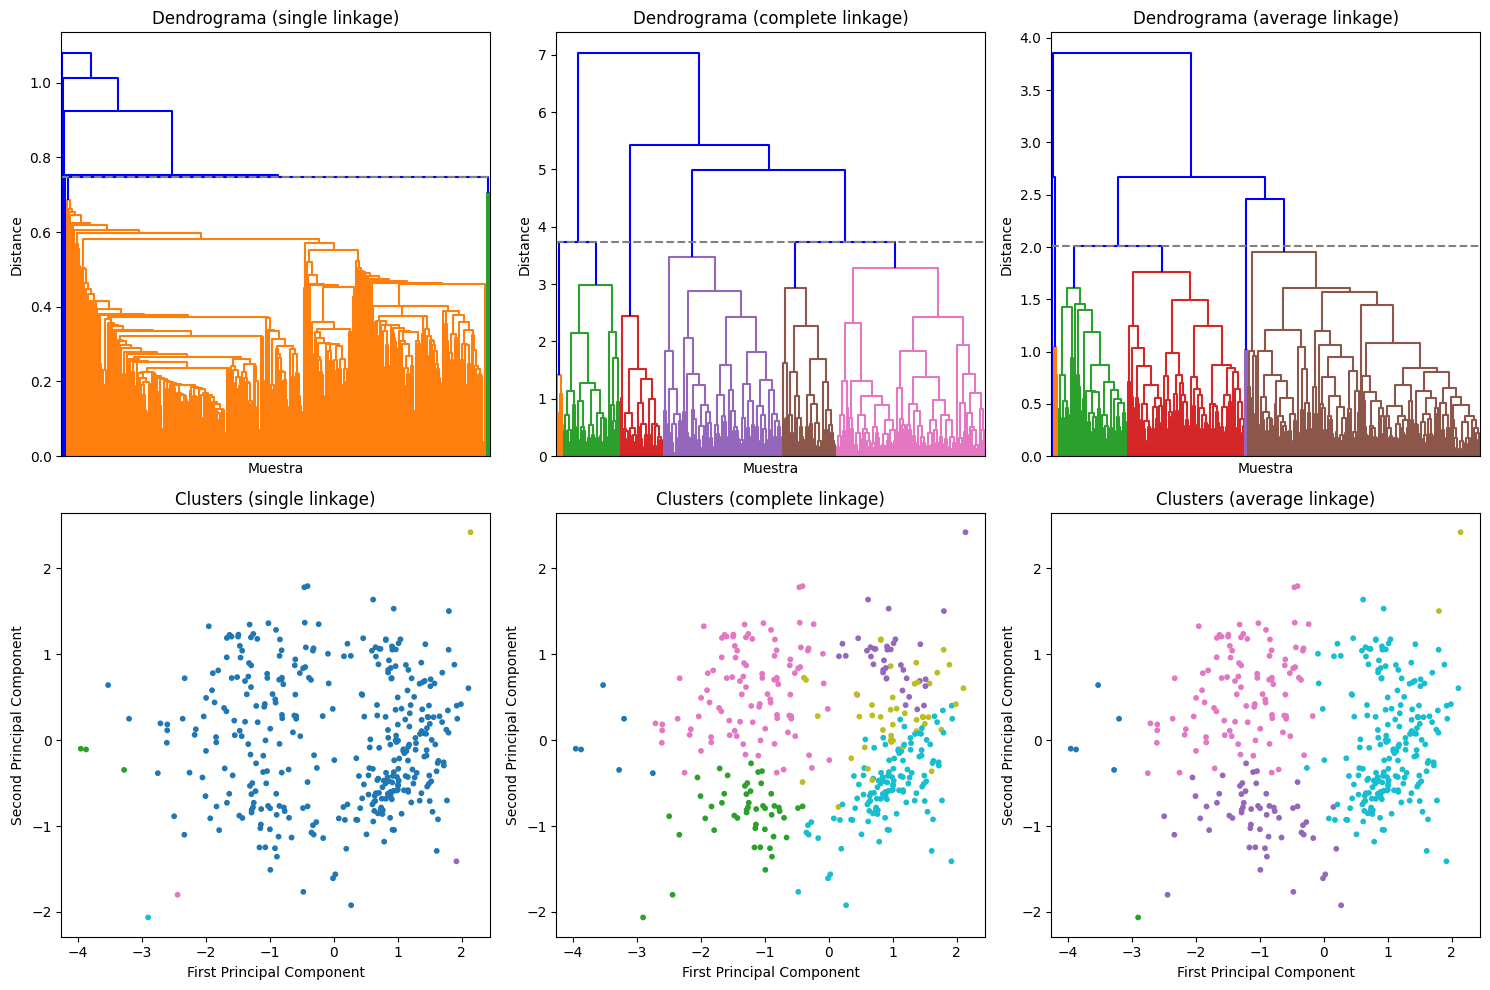

In [53]:
# Crear figura para los dendrogramas y scatter plots
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i, method in enumerate(linkage_methods):
    # Aplicar clustering jerárquico
    Z = linkage(X_genes_pca, method=method)
    y_pred = fcluster(Z, t=6, criterion='maxclust')

    # Graficar el dendrograma con línea de corte y 6 clusters
    axs[0, i].set_title(f'Dendrograma ({method} linkage)')
    plot_dendrogram_with_cut(Z, axs[0, i], n_clusters=6)
    axs[0, i].set_xticks([])

    # Scatter plot de los primeros dos componentes principales
    scatter = axs[1, i].scatter(X_genes_pca[:, 0], X_genes_pca[:, 1], c=y_pred, cmap='tab10', s=10)
    axs[1, i].set_title(f'Clusters ({method} linkage)')
    axs[1, i].set_xlabel('First Principal Component')
    axs[1, i].set_ylabel('Second Principal Component')

    # Comparar con K-Means
    cont_table = pd.crosstab(y_pred, kmeans_labels, rownames=['Cluster jerárquico'], colnames=['Cluster K-Means'])
    _, class_match = linear_sum_assignment(-cont_table)
    matched_labels = [class_match[label - 1] for label in y_pred]
    direct_agreement = accuracy_score(kmeans_labels, matched_labels) * 100
    print(f"Direct agreement con K-Means ({method} linkage): {direct_agreement:.2f}%")

plt.tight_layout()
plt.show()

**¿El método jerárquico encuentra los mismos grupos?**

Depende de la estrategia: con **complete linkage** coincide en un **77 %** con K-Means, con average en un 60 % y con single solo en un 29 %. *Single linkage* une los puntos por su vecino más cercano y tiende a formar un cluster gigante que se va "encadenando", por eso funciona mal cuando los grupos no están bien separados, como acá. Que complete linkage coincida en un 77 % indica que los 6 patrones no son un invento del K-Means.

## **9- Contexto clínico: los genes clave en una úlcera diabética**

Para poner los resultados en contexto uso el segundo dataset (GSE80178), que tiene los genes que cambian en el borde de úlceras de pie diabético respecto de la piel sana. Me fijo solo en los **genes clave** de la respuesta de los queratinocitos a la corriente: ¿están alterados en una herida real que no cicatriza?

En el formato de Affymetrix un fold change de **-3,6** quiere decir que el gen está **3,6 veces más bajo** en la úlcera. Lo paso a log2 para poder compararlo con mis resultados.

In [54]:
dfu = pd.read_csv('GSE80178_further_processed_data.txt', sep='\t')
print(dfu.columns.tolist())
dfu


['Transcript Cluster ID', 'DFU Bi-weight Avg Signal (log2)', 'FS Bi-weight Avg Signal (log2)', 'Fold Change (linear) (DFU vs. FS)', 'ANOVA p-value (DFU vs. FS)', 'FDR p-value (DFU vs. FS)', 'Gene Symbol', 'Description', 'TC Comment']


,Transcript Cluster ID,DFU Bi-weight Avg Signal (log2),FS Bi-weight Avg Signal (log2),Fold Change (linear) (DFU vs. FS),ANOVA p-value (DFU vs. FS),FDR p-value (DFU vs. FS),Gene Symbol,Description,TC Comment
0,16761012,8.51,10.36,-3.60,1.400000e-03,0.007153,A2M,alpha-2-macroglobulin,NaN
1,16947045,5.30,8.21,-7.51,1.314000e-03,0.006852,AADAC,arylacetamide deacetylase (esterase),NaN
2,16947026,5.84,9.61,-13.58,1.760000e-04,0.001893,AADACL2,arylacetamide deacetylase-like 2,NaN
3,16981444,5.66,7.01,-2.54,1.500000e-05,0.000472,AADAT,aminoadipate aminotransferase,NaN
4,17062280,7.10,8.55,-2.72,5.000000e-06,0.000259,AASS,aminoadipate-semialdehyde synthase,NaN
...,...,...,...,...,...,...,...,...,...
5867,16936803,3.15,4.31,-2.22,5.640000e-04,0.003940,NaN,NaN,NaN
5868,16936640,8.53,6.36,4.48,3.500000e-05,0.000751,NaN,NaN,NaN
5869,16935500,5.07,3.34,3.31,1.950000e-07,0.000052,NaN,NaN,NaN
5870,16943178,7.75,6.48,2.40,2.100000e-05,0.000553,NaN,NaN,NaN


In [55]:
# Sacar los transcritos sin nombre de gen
dfu = dfu.dropna(subset=['Gene Symbol']).copy()

# Pasar el fold change lineal (con signo) a log2
# Si es positivo se aplica log2 directly, si es negativo se aplica log2 al valor absoluto y se le vuelve a poner signo negativo
fc_lineal = dfu['Fold Change (linear) (DFU vs. FS)']
dfu['log2FC_ulcera'] = np.where(fc_lineal >= 0, np.log2(fc_lineal), -np.log2(np.abs(fc_lineal)))

# Si un gen aparece varias veces, me quedo con la mediana
ulcera = dfu.groupby('Gene Symbol')['log2FC_ulcera'].median()

print("Genes alterados en la úlcera:", len(ulcera))
print("Suben:", (ulcera > 0).sum(), "| Bajan:", (ulcera < 0).sum())

Genes alterados en la úlcera: 3903
Suben: 969 | Bajan: 2934


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


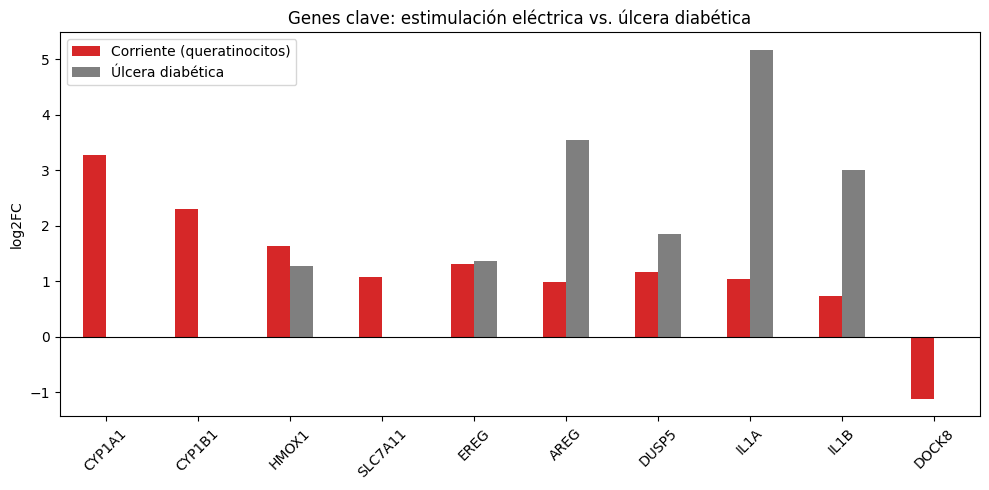

,Corriente (queratinocitos),Úlcera diabética
CYP1A1,3.28,NaN
CYP1B1,2.31,NaN
HMOX1,1.64,1.28
SLC7A11,1.08,NaN
EREG,1.31,1.36
AREG,0.98,3.55
DUSP5,1.17,1.84
IL1A,1.05,5.17
IL1B,0.74,3.01
DOCK8,-1.12,NaN


In [56]:
q_tabla = resultados['Queratinocitos']
# Los genes clave de la estimulación en la úlcera
genes_clave = ['CYP1A1', 'CYP1B1', 'HMOX1', 'SLC7A11', 'EREG', 'AREG', 'DUSP5', 'IL1A', 'IL1B', 'DOCK8']

clave = pd.DataFrame({'Corriente (queratinocitos)': q_tabla.reindex(genes_clave)['log2FC'],
                      'Úlcera diabética': ulcera.reindex(genes_clave)})

clave.plot(kind='bar', figsize=(10, 5), color=['tab:red', 'tab:gray'])
plt.axhline(0, color='black', lw=0.8)
plt.ylabel('log2FC')
plt.title('Genes clave: estimulación eléctrica vs. úlcera diabética')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

clave.round(2)

**¿Y los genes clave?**

Los genes que el campo eléctrico activa en los queratinocitos se dividen en dos grupos:

1. **CYP1A1, CYP1B1, SLC7A11 y DOCK8 no aparecen entre los genes alterados en la úlcera.** Como GEO tiene solo la tabla de genes significativos (FDR < 0,05 y al menos 2 veces de cambio), esto quiere decir que no cambian de forma significativa, no que esté demostrado que no cambian. CYP1A1 y CYP1B1, que son la respuesta más fuerte a la corriente, son enzimas de detoxificación que se activan por el receptor AhR (receptor de aril hidrocarburos). Esta parte de la respuesta parece **propia de la estimulación eléctrica**.
2. **HMOX1, EREG, AREG, DUSP5, IL1A e IL1B suben también en la úlcera** (AREG e IL1B suben con la corriente un poco menos del doble: 0,98 y 0,74), y en la úlcera suben todavía más (IL1A unas 36 veces, AREG unas 12). Son genes de **respuesta a la herida**: EREG y AREG activan el receptor EGFR (proliferación y migración), DUSP5 se induce cuando se activa la vía MAPK-ERK, HMOX1 protege del estrés oxidativo e IL1A/IL1B son señales de alarma de daño.

Lo que muestra esto es que **la corriente activa en los queratinocitos parte del programa de "célula activada por una herida"**, justamente la vía **EGFR → MAPK-ERK** que propone la revisión de Preetam et al. (2024) como mecanismo. En la úlcera ese programa ya está encendido (de hecho muy encendido, por la inflamación crónica), así que no se puede decir que la estimulación "corrija" la úlcera. Para eso habría que medir la respuesta en tejido de úlcera estimulado.

**¿La respuesta es al campo eléctrico o a otra cosa?** HMOX1 y SLC7A11 son genes clásicos de respuesta al estrés oxidativo (vía NRF2), y AhR, el receptor que activa CYP1A1 y CYP1B1, también se activa con productos de la oxidación. Un campo de 14.000 V podría generar ozono o especies reactivas de oxígeno en el medio de cultivo. Como las células sham no reciben el campo, este diseño no permite separar el efecto directo del campo del efecto de esos subproductos químicos. Para eso haría falta, por ejemplo, un control con antioxidantes o midiendo especies reactivas en el medio.

## **10- Candidato a biomarcador**

Para el proyecto de Biosensores busco, entre los genes que **suben en los queratinocitos** con la corriente, uno que sirva como biomarcador para saber si las células están respondiendo a la estimulación. Los criterios son:

1. Que produzca una **proteína secretada** o liberada al exterior, para que se pueda medir en el líquido de la herida (exudado).
2. Que suba de forma **consistente en las 3 réplicas**.
3. Que el **paper original también lo reporte**, como validación independiente.
4. Que esté relacionado con el **mecanismo de cicatrización** que propone la literatura.

In [57]:
# Genes que suben en queratinocitos, con sus 3 réplicas y si están alterados en la úlcera
sube_q = q_tabla[q_tabla['cambio'] == 'Sube'][['log2FC']].copy()
sube_q = sube_q.join(datos_limpios[grupos['Queratinocitos']])
sube_q['en_ulcera'] = ulcera.reindex(sube_q.index)
sube_q['UniProt'] = 'https://www.uniprot.org/uniprotkb?query=' + sube_q.index + '+AND+organism_id:9606'

sube_q.to_csv('candidatos_biomarcador.csv')
sube_q.sort_values('log2FC', ascending=False).head(25).round(2)

,log2FC,Querat_1,Querat_2,Querat_3,en_ulcera,UniProt
GENE_SYMBOL,,,,,,
CYP1A1,3.28,3.43,3.28,3.17,NaN,https://www.uniprot.org/uniprotkb?query=CYP1A1...
CYP1B1,2.31,2.31,2.40,2.28,NaN,https://www.uniprot.org/uniprotkb?query=CYP1B1...
C9orf92,1.71,1.71,0.64,1.86,NaN,https://www.uniprot.org/uniprotkb?query=C9orf9...
FGR,1.68,1.94,1.68,0.70,NaN,https://www.uniprot.org/uniprotkb?query=FGR+AN...
TM6SF1,1.64,1.64,1.68,0.65,NaN,https://www.uniprot.org/uniprotkb?query=TM6SF1...
HMOX1,1.64,1.99,1.42,1.64,1.28,https://www.uniprot.org/uniprotkb?query=HMOX1+...
OR1A2,1.58,1.58,0.78,1.61,NaN,https://www.uniprot.org/uniprotkb?query=OR1A2+...
ARHGAP31,1.58,0.78,1.58,1.98,-1.73,https://www.uniprot.org/uniprotkb?query=ARHGAP...
ZFAND4,1.45,0.92,1.45,1.67,-1.64,https://www.uniprot.org/uniprotkb?query=ZFAND4...


**Genes candidatos (consultado en UniProt):**

| Gen | log2FC (3 réplicas) | Función | Localización | ¿Se puede medir afuera? |
|---|---|---|---|---|
| CYP1A1 | 3,28 (3,43 / 3,28 / 3,17) | Citocromo P450, detoxificación de compuestos (vía AhR) | Retículo endoplasmático | No |
| CYP1B1 | 2,31 | Citocromo P450, igual que CYP1A1 | Retículo endoplasmático | No |
| HMOX1 | 1,64 | Hemo oxigenasa, defensa contra estrés oxidativo | Retículo endoplasmático | No |
| **EREG** | **1,31 (1,31 / 1,19 / 1,38)** | **Epirregulina, ligando del EGFR: estimula proliferación y migración de queratinocitos** | **Se corta de la membrana y se libera (secretada)** | **Sí** |
| **IL1A** | **1,05 (1,05 / 1,00 / 1,11)** | **Interleuquina 1α, señal de alarma de daño** | **Citoplasma, se libera al exterior** | **Sí** |
| SLC7A11 | 1,08 | Transportador cistina/glutamato, antioxidante | Membrana | No |
| LCN12 | 1,44 (1,28 / 1,53 / 1,44) | Lipocalina, transporte de moléculas hidrofóbicas | Secretada | Sí |
| NTN1 | 1,26 (1,00 / — / 1,52) | Netrina 1, guía axonal y angiogénesis | Secretada | Sí |
| FCN3 | 1,43 (1,43 / 0,81 / 1,78) | Ficolina 3, vía de las lectinas del complemento | Secretada | Sí |


Hay varios genes que cumplen el criterio 1 (EREG, IL1A, LCN12, NTN1 y FCN3). **Elijo EREG (epirregulina)** porque es el único que cumple los 4:
- Se **libera al exterior**: se sintetiza unida a la membrana y una proteasa la corta y la libera.
- Sube en las **3 réplicas** con valores muy parecidos (alrededor de 2,5 veces).
- El **paper original la reporta** en queratinocitos.
- **Activa el EGFR**, la vía que propone la literatura para la migración de los queratinocitos y el cierre de la herida.

LCN12 sube de forma igual de consistente, pero no está en el paper ni tiene relación conocida con la cicatrización. NTN1 tiene solo 2 réplicas válidas y FCN3 es más variable (0,81 en una réplica). IL1A cumple casi todo, pero es menos específica (ver abajo).

En la úlcera diabética EREG ya está alta (1,36 en log2) antes de cualquier tratamiento. Entonces un biosensor no puede usar un valor fijo de EREG para decir "está respondiendo": tendría que medir el **cambio relativo** en el mismo paciente, antes y después de la estimulación. IL1A queda como segundo candidato, pero es menos específico porque en la úlcera ya está 36 veces aumentado por la inflamación.

## **Conclusiones**

**Respecto de la hipótesis:** se confirma en lo principal, con un matiz importante. (1) Los queratinocitos tienen un programa propio, distinto del de los otros dos tipos celulares. (2) Ese programa incluye genes de la vía EGFR → MAPK-ERK (EREG, DUSP5 y AREG en el umbral) y de estrés oxidativo (HMOX1, SLC7A11). (3) Parte de ese programa está activado en la úlcera diabética. (4) Hay un candidato a biomarcador secretado (EREG). El matiz es que la respuesta más fuerte, CYP1A1 y CYP1B1 por la vía AhR, **no estaba prevista en la hipótesis**, y no aparece alterada en la úlcera.

Cuando los queratinocitos reciben el campo eléctrico, la respuesta más fuerte y reproducible es la activación de **CYP1A1 y CYP1B1** (unas 10 y 5 veces, casi idéntico en las 3 réplicas), enzimas de detoxificación que se encienden por el receptor AhR. Además se activa un grupo de genes de **célula activada por una herida**: el ligando del EGFR **EREG** (y **AREG**, casi en el umbral), **DUSP5** (señal de que se activó la vía MAPK-ERK), defensas antioxidantes (**HMOX1, SLC7A11**) e **IL1A**. Esto apoya el mecanismo **EGFR → MAPK-ERK** que propone la literatura para explicar cómo la estimulación eléctrica ayuda a cerrar heridas.

Del control de calidad (correlación, PCA y clustering) saqué que los **queratinocitos** son los que responden de forma más clara y consistente: sus réplicas son las que más se parecen y el K-Means las agrupa juntas sin error. Los **fibroblastos** fueron los menos confiables: Fibro_1 y Fibro_3 quedan solas en el clustering jerárquico, y Fibro_3 tenía una señal de inflamación que no aparecía en las otras muestras, así que la saqué del análisis.

Con el **Random Forest** comprobé que con 9 muestras no se puede entrenar un clasificador (precisión OOB de 0,56), por eso trabajé con métodos no supervisados.

Reproduje **7 de los 9 genes** que reportó el paper original con el mismo signo, lo que valida el análisis.

Cada tipo celular responde **distinto**: el K-Means de los genes encontró 6 patrones, 5 de ellos limpios (sube o baja solo en un tipo celular), y los 11 genes que cambian en los 3 parecen un artefacto del colorante.

Al mirar los genes clave en una úlcera de pie diabético, CYP1A1 y CYP1B1 no están alterados, así que serían propios de la estimulación, mientras que los genes de respuesta a la herida (EREG, AREG, DUSP5, HMOX1, IL1A) ya están aumentados en la úlcera.

Como biomarcador para el biosensor elegiría **EREG**: sube en las 3 réplicas, se libera al exterior y está relacionado con el mecanismo de cierre de heridas. Habría que medir su cambio en el mismo paciente antes y después de estimular, porque en la úlcera ya está elevado.

**Limitaciones:**
- Solo 3 réplicas por tipo celular (2 en fibroblastos, y además las dos menos parecidas entre sí). Con este n, el t-test con corrección FDR tiene muy poca potencia (solo 5 genes pasan FDR < 0,05 en queratinocitos, y ni siquiera CYP1A1)), así que el criterio principal fue la consistencia entre réplicas, y algunos genes pueden ser falsos positivos. Los candidatos habría que confirmarlos en el laboratorio (por ejemplo, con RT-qPCR) y medir la proteína EREG en el sobrenadante del cultivo.
- El estímulo es de **alto voltaje (14000 V, 90 Hz)**, distinto al de un parche de baja intensidad. Los resultados muestran cómo responden las células al campo, no si un parche funciona.
- Son **células en cultivo** y una sola línea por tipo celular (HaCaT es una línea inmortalizada), sin la interacción que hay en una herida real.
- Se midió **un solo tiempo** (6 horas).
- El microarray de dos colores **sin dye swap** puede generar artefactos del colorante.
- Del dataset de la úlcera solo tenía la **tabla de resultados**, no los datos de cada paciente, así que no pude hacer mi propio PCA ni clustering de los pacientes.
- El diseño no permite separar el efecto directo del campo eléctrico del de posibles subproductos (ozono o especies reactivas) generados por el equipo de alto voltaje.

## **Referencias**

- Aoki M. et al. (2019). Cytochrome P450 genes play central roles in transcriptional response by keratinocytes to a high-voltage alternating current electric field. *Bioelectrochemistry*. doi:10.1016/j.bioelechem.2018.11.014
- Ramirez H.A. et al. (2018). Staphylococcus aureus triggers induction of miR-15B-5P to diminish DNA repair and deregulate inflammatory response in diabetic foot ulcers. *Journal of Investigative Dermatology*, 138(5), 1187-1196. doi:10.1016/j.jid.2017.11.038
- Dobbin K.K. et al. (2005). Characterizing dye bias in microarray experiments. Bioinformatics, 21(10), 2430-2437
- GEO: GSE110830 (https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE110830) y GSE80178 (https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE80178)